# **TCC - Problema de Alocação de Bases de Ambulâncias**


# 1. Simulador de dados sintéticos: geração de mapa com as ocorrências e seus tempos de processamento

## 1.1 - Geração de pontos em um mapa a partir do GeoJSON do município selecionado

In [ ]:
# 0. Instalação de dependências (rodar apenas uma vez, no Colab)
# ==========================================================
# !pip -q install geopandas shapely pyogrio pandas numpy folium

import geopandas as gpd
import pandas as pd
import numpy as np
import random
from shapely.geometry import Point
import folium

# ==========================================================
# 1. Carregar a malha municipal de SP (todos os 645 municípios)
# ==========================================================
# O arquivo abaixo contém o contorno de TODOS os municípios de SP.
# "35" é o código IBGE do estado de São Paulo -- não precisamos
# buscar um GeoJSON separado para Campinas, só filtrar este.
url = "https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-35-mun.json"
gdf = gpd.read_file(url)
gdf = gdf.sort_values("name").reset_index(drop=True)
print("Municípios carregados:", len(gdf))

# ==========================================================
# 2. Filtrar apenas o município de Campinas
# ==========================================================
gdf_campinas = gdf[gdf["name"] == "Campinas"].reset_index(drop=True)

# Fallback de segurança: caso o nome esteja sem acentuação correta no dataset
if gdf_campinas.empty:
    gdf_campinas = gdf[
        gdf["name"].str.contains("Campinas", case=False, na=False)
    ].reset_index(drop=True)

if gdf_campinas.empty:
    raise ValueError(
        "Município de Campinas não encontrado no GeoJSON. "
        "Verifique a coluna 'name' do dataset."
    )

poligono_campinas = gdf_campinas.iloc[0]["geometry"]

# ==========================================================
# 3. Detalhes do gdf_campinas (print final solicitado)
# ==========================================================
minx, miny, maxx, maxy = poligono_campinas.bounds
centro_lat = poligono_campinas.centroid.y
centro_lon = poligono_campinas.centroid.x

print("\n" + "=" * 60)
print("DETALHES DO MUNICÍPIO DE CAMPINAS (gdf_campinas)")
print("=" * 60)
print(gdf_campinas)
print("\nColunas disponíveis:", list(gdf_campinas.columns))
print(f"\nNome do município : {gdf_campinas.iloc[0]['name']}")
print(f"Código IBGE       : {gdf_campinas.iloc[0]['id']}")
print(f"Área do polígono   : {poligono_campinas.area:.6f} (graus²,"
      f" não é km² -- unidade geográfica bruta)")
print(f"Bounding box       : min_lon={minx:.5f}, min_lat={miny:.5f}, "
      f"max_lon={maxx:.5f}, max_lat={maxy:.5f}")
print(f"Centroide          : lat={centro_lat:.5f}, lon={centro_lon:.5f}")
print("=" * 60)

# ==========================================================
# 4. Função para gerar pontos dentro do polígono (rejection sampling)
# ==========================================================
def gerar_pontos_no_poligono(poligono, n_pontos=500, seed=0):
    """
    Gera 'n_pontos' pontos aleatórios uniformemente distribuídos
    dentro de um polígono, usando rejection sampling:
    sorteia pontos dentro do bounding box e só aceita os que
    caem de fato dentro do polígono real.
    """
    random.seed(seed)
    minx, miny, maxx, maxy = poligono.bounds
    pontos = []
    while len(pontos) < n_pontos:
        x = random.uniform(minx, maxx)
        y = random.uniform(miny, maxy)
        ponto = Point(x, y)
        if poligono.contains(ponto):
            pontos.append((y, x))  # (lat, lon)
    return pontos

# ==========================================================
# 5. Gerar os pontos sintéticos de demanda para Campinas
# ==========================================================
N_PONTOS = 150

SEED_OCORRENCIAS = 1
SEED_TEMPOS = 42

pontos_campinas = gerar_pontos_no_poligono(
    poligono_campinas, n_pontos=N_PONTOS, seed=SEED_OCORRENCIAS
)

print(f"\nPontos sintéticos gerados para Campinas: {len(pontos_campinas)}")
print(f"Seed utilizada: {SEED_OCORRENCIAS}")
print("Primeiros 5 pontos (lat, lon):", pontos_campinas[:5])

# ==========================================================
# 6. Visualização automática em mapa interativo (Folium)
# ==========================================================
from getpass import getpass

CARTO_API_KEY = getpass("Cole sua chave de API do CARTO: ")

CARTO_TILES = (
    "https://basemaps.cartocdn.com/rastertiles/"
    f"light_all/{{z}}/{{x}}/{{y}}.png?key={CARTO_API_KEY}"
)

CARTO_ATTR = (
    '© <a href="https://www.openstreetmap.org/copyright">'
    'OpenStreetMap</a> contributors, '
    '© <a href="https://carto.com/attribution/">CARTO</a>'
)

mapa = folium.Map(location=[centro_lat, centro_lon], zoom_start=11, tiles=CARTO_TILES, attr=CARTO_ATTR)

folium.GeoJson(
    poligono_campinas,
    name="Limite municipal - Campinas",
    style_function=lambda x: {"color": "blue", "weight": 2, "fillOpacity": 0.1},
).add_to(mapa)

bbox = [
    [miny, minx],
    [miny, maxx],
    [maxy, maxx],
    [maxy, minx],
    [miny, minx],
]
folium.PolyLine(bbox, color="red", weight=2, tooltip="Bounding Box").add_to(mapa)

for lat, lon in pontos_campinas:
    folium.CircleMarker(
        location=[lat, lon],
        radius=3,
        color="green",
        fill=True,
        fill_opacity=0.7,
    ).add_to(mapa)

folium.Marker(
    [centro_lat, centro_lon],
    popup=(
        f"Município: {gdf_campinas.iloc[0]['name']}<br>"
        f"Método (Passo 1): K-Means<br>"
        f"Pontos gerados: {len(pontos_campinas)}<br>"
        f"Seed: {SEED_OCORRENCIAS}"
    ),
).add_to(mapa)

folium.LayerControl(collapsed=False).add_to(mapa)

mapa.save("mapa_campinas_passo1.html")
print("\nMapa interativo salvo em: mapa_campinas_passo1.html")

mapa  # <- no Colab, isso renderiza o mapa interativo diretamente na célula

Municípios carregados: 645

DETALHES DO MUNICÍPIO DE CAMPINAS (gdf_campinas)
        id      name description  \
0  3509502  Campinas    Campinas   

                                            geometry  
0  POLYGON ((-47.05813 -22.73542, -47.058 -22.738...  

Colunas disponíveis: ['id', 'name', 'description', 'geometry']

Nome do município : Campinas
Código IBGE       : 3509502
Área do polígono   : 0.070039 (graus², não é km² -- unidade geográfica bruta)
Bounding box       : min_lon=-47.24451, min_lat=-23.06104, max_lon=-46.81443, max_lat=-22.72925
Centroide          : lat=-22.88356, lon=-47.04343

Pontos sintéticos gerados para Campinas: 150
Seed utilizada: 1
Primeiros 5 pontos (lat, lon): [(-22.911902221406184, -47.0314347650678), (-22.79934736965969, -46.96427466813418), (-22.82163831539546, -47.052959271077334), (-22.920984881572174, -47.15135590699864), (-22.896533185574402, -47.05618468545892)]
Cole sua chave de API do CARTO: ··········

Mapa interativo salvo em: mapa_campinas_p

# 1.2. Adicionando os tempos de processamento aos pontos adicionados

- Apenas clusterização (sem P-Mediana/P-Centro/Capacitado)

base da ambulância = centroide geométrico do cluster

- Distância: será calculada via OSRM (rota real de carro), não Haversine.
- O tempo T3 (deslocamento base -> ocorrência) NÃO é calculado nesta seção,
  porque ele depende dos CENTROS DE CLUSTER, que só existem depois da
  clusterização (Seção 2) e do cálculo de distância via OSRM (Seção 3).
  Aqui geramos apenas T1, T2, T4, T5 (tempos que não dependem da posição
  da base), exatamente como no notebook original -- T3 será somado ao
  Total_Time somente na Seção 3, corrigindo a lacuna identificada no
  notebook de referência.


In [ ]:
import numpy as np
import pandas as pd
import random
from enum import Enum
from typing import List, Tuple
from shapely.geometry import Point
import matplotlib.pyplot as plt
import seaborn as sns

class DistKind(Enum):
    EXPONENTIAL = 'exponential'
    NORMAL = 'normal'
    LOGNORMAL = 'lognormal'

def generate_time_value(dist_kind, p1, p2, p3):
    """
    Gera um único valor de tempo, de acordo com a distribuição escolhida.
    p1, p2, p3 são os parâmetros daquela distribuição.
    """
    if dist_kind == DistKind.EXPONENTIAL:
        return np.random.exponential(scale=p1)
    elif dist_kind == DistKind.NORMAL:
        return np.random.normal(loc=p1, scale=p2)
    elif dist_kind == DistKind.LOGNORMAL:
        return np.random.lognormal(mean=p1, sigma=p2)
    else:
        raise ValueError(f"Distribuição desconhecida: {dist_kind}")

def generate_occurrences(
    city_row: pd.Series,
    n: int,
    city_geometry: 'Polygon',
    dist_t1: DistKind, t1_p1: float, t1_p2: float, t1_p3: float,
    dist_t2: DistKind, t2_p1: float, t2_p2: float, t2_p3: float,
    dist_t4: DistKind, t4_p1: float, t4_p2: float, t4_p3: float,
    dist_t5: DistKind, t5_p1: float, t5_p2: float, t5_p3: float,
    existing_pts: List[Tuple[float, float]] = None,
    seed: int = None,
    seed_tempos: int = None,
) -> pd.DataFrame:
    """
    Gera um DataFrame de ocorrências com os tempos de processamento simulados
    (T1, T2, T4, T5). O T3 (deslocamento) NÃO é gerado aqui -- ele depende
    do centro de cluster, calculado somente na Seção 2/3.
    """
    if existing_pts:
        points = existing_pts
    else:
        if seed is not None:
            random.seed(seed)
        minx, miny, maxx, maxy = city_geometry.bounds
        points = []
        while len(points) < n:
            x = random.uniform(minx, maxx)
            y = random.uniform(miny, maxy)
            p = Point(x, y)
            if city_geometry.contains(p):
                points.append((y, x))

    if seed_tempos is not None:
      np.random.seed(seed_tempos)

    data = []
    for i, (lat, lon) in enumerate(points):
        t1 = generate_time_value(dist_t1, t1_p1, t1_p2, t1_p3)
        t2 = generate_time_value(dist_t2, t2_p1, t2_p2, t2_p3)
        t4 = generate_time_value(dist_t4, t4_p1, t4_p2, t4_p3)
        t5 = generate_time_value(dist_t5, t5_p1, t5_p2, t5_p3)
        data.append({
            'ID': f"{city_row['municipio_nome']}-{i:04d}",
            'lat': lat,
            'lon': lon,
            'T1': t1,
            'T2': t2,
            'T4': t4,
            'T5': t5,
            'municipio_nome': city_row['municipio_nome'],
            'Populacao_2022': city_row.get('Populacao_2022', None),
        })
    return pd.DataFrame(data)

def create_occurrence_table_from_points(
    input_pontos: List[Tuple[float, float]],
    city_info: pd.Series,
    t1_dist=DistKind.EXPONENTIAL, t1_p1=5.0, t1_p2=0.0, t1_p3=0.0,
    t2_dist=DistKind.NORMAL, t2_p1=2.0, t2_p2=0.5, t2_p3=0.0,
    t4_dist=DistKind.NORMAL, t4_p1=10.0, t4_p2=3.0, t4_p3=0.0,
    t5_dist=DistKind.LOGNORMAL, t5_p1=2.3, t5_p2=0.5, t5_p3=0.0,
    seed_tempos: int = None,
) -> pd.DataFrame:
    """
    Cria a tabela de ocorrências a partir da lista de pontos de Campinas
    gerada na Seção 1.1, adicionando os tempos T1, T2, T4, T5 simulados.
    """
    if 'Populacao_2022' not in city_info:
        city_info = city_info.copy()
        city_info['Populacao_2022'] = None
    return generate_occurrences(
        city_row=city_info,
        n=len(input_pontos),
        city_geometry=city_info['geometry'],
        dist_t1=t1_dist, t1_p1=t1_p1, t1_p2=t1_p2, t1_p3=t1_p3,
        dist_t2=t2_dist, t2_p1=t2_p1, t2_p2=t2_p2, t2_p3=t2_p3,
        dist_t4=t4_dist, t4_p1=t4_p1, t4_p2=t4_p2, t4_p3=t4_p3,
        dist_t5=t5_dist, t5_p1=t5_p1, t5_p2=t5_p2, t5_p3=t5_p3,
        existing_pts=input_pontos,
        seed_tempos=seed_tempos,
    )

## 1.3. Exemplo de uso da nova função com a variável 'pontos'

In [ ]:
# Exemplo de uso da função com os pontos de Campinas
# (aqui sim os dados são efetivamente gerados, reaproveitando os pontos
# 'pontos_campinas' já criados na Seção 1.1 via rejection sampling)
# ==========================================================================
campinas_info = pd.Series({
    'municipio_nome': gdf_campinas.iloc[0]['name'],
    'geometry': poligono_campinas,
    # População de Campinas, Censo Demográfico 2022 (IBGE), contagem oficial (1.139.047 habitantes).
    'Populacao_2022': 1139047,
})

df_ocorrencias_campinas = create_occurrence_table_from_points(
    input_pontos=pontos_campinas,
    city_info=campinas_info,
    seed_tempos=SEED_TEMPOS,
)

print("Tabela de ocorrências geradas para Campinas:")
try:
    display(df_ocorrencias_campinas.head())
except NameError:
    print(df_ocorrencias_campinas.head())

print(f"Seed dos tempos: {SEED_TEMPOS}")
df_ocorrencias_campinas.info()

Tabela de ocorrências geradas para Campinas:


,ID,lat,lon,T1,T2,T4,T5,municipio_nome,Populacao_2022
0,Campinas-0000,-22.911902,-47.031435,2.346340,1.444060,10.956707,11.467542,Campinas,1139047
1,Campinas-0001,-22.799347,-46.964275,6.156250,2.505258,8.591577,13.082560,Campinas,1139047
2,Campinas-0002,-22.821638,-47.052959,1.003395,1.714310,7.227751,2.701279,Campinas,1139047
3,Campinas-0003,-22.920985,-47.151356,1.721115,2.475185,6.961507,11.671193,Campinas,1139047
4,Campinas-0004,-22.896533,-47.056185,1.727578,1.648328,3.581138,7.280959,Campinas,1139047


Seed dos tempos: 42
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              150 non-null    object 
 1   lat             150 non-null    float64
 2   lon             150 non-null    float64
 3   T1              150 non-null    float64
 4   T2              150 non-null    float64
 5   T4              150 non-null    float64
 6   T5              150 non-null    float64
 7   municipio_nome  150 non-null    object 
 8   Populacao_2022  150 non-null    int64  
dtypes: float64(6), int64(1), object(2)
memory usage: 10.7+ KB


## 1.4. Visualização das distribuições dos tempos simulados

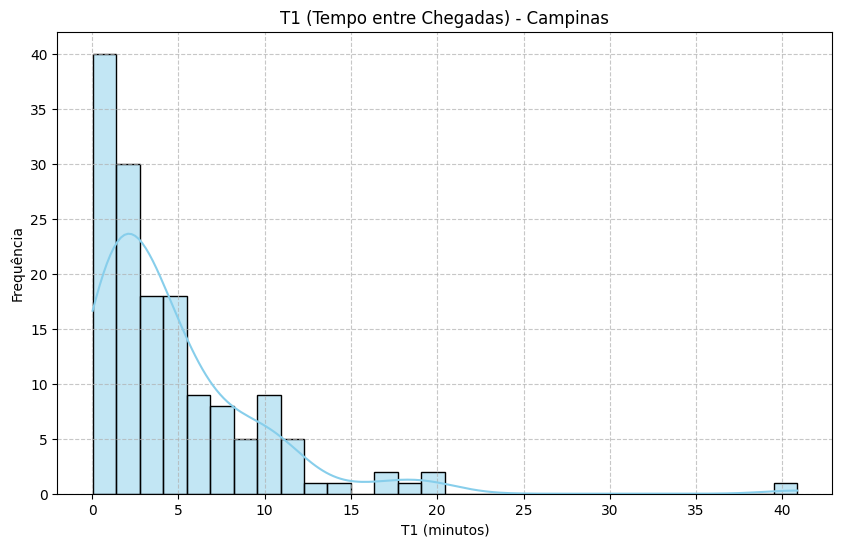

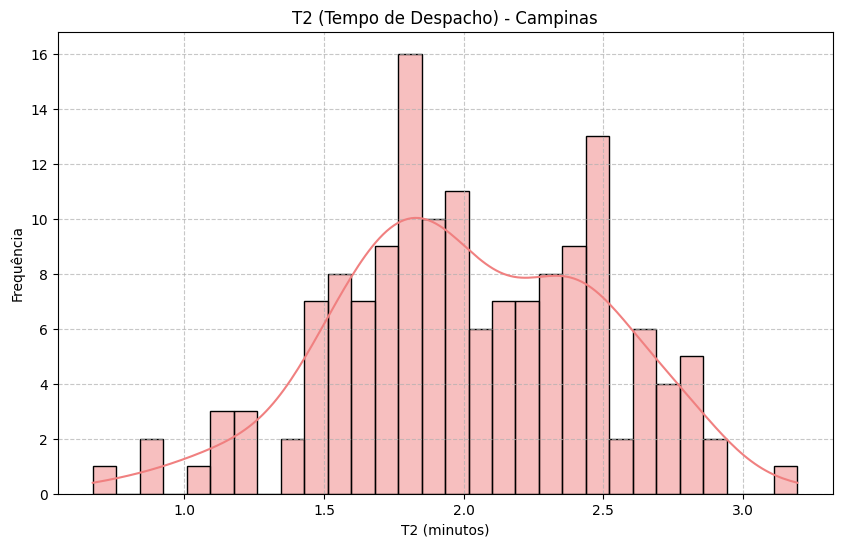

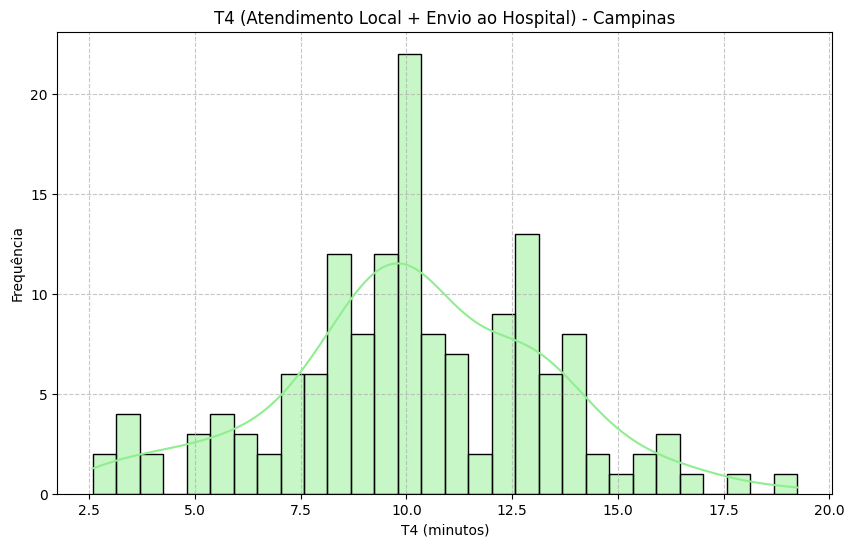

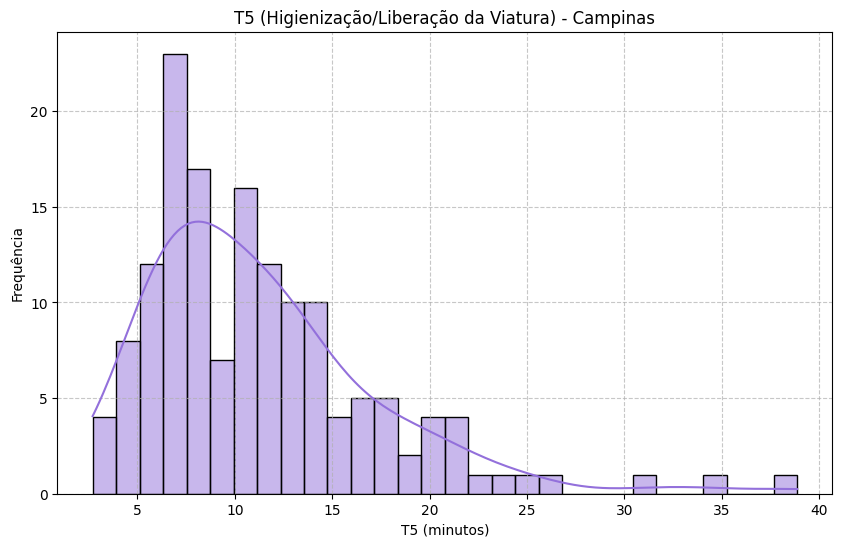


Gráficos de distribuição salvos na pasta atual: campinas_T1_distribuicao.png, campinas_T2_distribuicao.png, campinas_T4_distribuicao.png, campinas_T5_distribuicao.png


In [ ]:
# (histogramas de T1, T2, T4, T5 -- conferência visual de que cada
# distribuição simulada está com o formato esperado: Exponencial,
# Normal, Normal e Lognormal, respectivamente)
# ==========================================================================
tempos_config = [
    ('T1', 'skyblue', 'T1 (Tempo entre Chegadas) - Campinas'),
    ('T2', 'lightcoral', 'T2 (Tempo de Despacho) - Campinas'),
    ('T4', 'lightgreen', 'T4 (Atendimento Local + Envio ao Hospital) - Campinas'),
    ('T5', 'mediumpurple', 'T5 (Higienização/Liberação da Viatura) - Campinas'),
]

for coluna, cor, titulo in tempos_config:
    plt.figure(figsize=(10, 6))
    sns.histplot(df_ocorrencias_campinas[coluna], kde=True, bins=30, color=cor)
    plt.title(titulo)
    plt.xlabel(f'{coluna} (minutos)')
    plt.ylabel('Frequência')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.savefig(f'campinas_{coluna}_distribuicao.png', dpi=150)
    plt.show()

print("\nGráficos de distribuição salvos na pasta atual: "
      "campinas_T1_distribuicao.png, campinas_T2_distribuicao.png, "
      "campinas_T4_distribuicao.png, campinas_T5_distribuicao.png")

# 2. Cálculo dos clusters - K-Means para k=5

## 2.1. Aplicação de K-Means

In [ ]:
from sklearn.cluster import KMeans

MODEL_NAME = 'kmeans'
N_CLUSTERS = 5
RANDOM_STATE = 42
COLUNA_CLUSTER = f'{MODEL_NAME}{N_CLUSTERS}'

def aplicar_kmeans(df_ocorrencias: pd.DataFrame, n_clusters: int,
                    coluna_cluster: str, random_state: int = 42):
    """
    Aplica o K-Means sobre as coordenadas (lat, lon) das ocorrências.
    """
    df_com_cluster = df_ocorrencias.rename(
        columns={'lat': 'Latitude', 'lon': 'Longitude'}
    ).copy()
    X = df_com_cluster.loc[:, ['Latitude', 'Longitude']].values
    modelo = KMeans(
        n_clusters=n_clusters,
        init='k-means++',
        n_init=10,
        random_state=random_state,
    )
    rotulos = modelo.fit_predict(X)
    df_com_cluster[coluna_cluster] = rotulos + 1
    centers_dict = {
        str(i + 1): modelo.cluster_centers_[i]
        for i in range(n_clusters)
    }
    return df_com_cluster, centers_dict

df_accidents, centers_dict = aplicar_kmeans(
    df_ocorrencias_campinas,
    n_clusters=N_CLUSTERS,
    coluna_cluster=COLUNA_CLUSTER,
    random_state=RANDOM_STATE,
)

print(f"K-Means aplicado com k={N_CLUSTERS} (Campinas)")
print(f"Coluna de cluster criada: '{COLUNA_CLUSTER}'")
print("\nCentros dos clusters (base de ambulância = centroide):")
for cluster_id, centro in centers_dict.items():
    print(f"  Cluster {cluster_id}: lat={centro[0]:.5f}, lon={centro[1]:.5f}")

print("\nQuantidade de ocorrências por cluster:")
print(df_accidents[COLUNA_CLUSTER].value_counts().sort_index())

print("\nAmostra da tabela com o cluster atribuído:")
try:
    display(df_accidents.head())
except NameError:
    print(df_accidents.head())

K-Means aplicado com k=5 (Campinas)
Coluna de cluster criada: 'kmeans5'

Centros dos clusters (base de ambulância = centroide):
  Cluster 1: lat=-22.86797, lon=-47.12458
  Cluster 2: lat=-22.90451, lon=-47.03432
  Cluster 3: lat=-22.85950, lon=-46.91342
  Cluster 4: lat=-22.99243, lon=-47.13882
  Cluster 5: lat=-22.77929, lon=-47.00613

Quantidade de ocorrências por cluster:
kmeans5
1    30
2    22
3    43
4    31
5    24
Name: count, dtype: int64

Amostra da tabela com o cluster atribuído:


,ID,Latitude,Longitude,T1,T2,T4,T5,municipio_nome,Populacao_2022,kmeans5
0,Campinas-0000,-22.911902,-47.031435,2.346340,1.444060,10.956707,11.467542,Campinas,1139047,2
1,Campinas-0001,-22.799347,-46.964275,6.156250,2.505258,8.591577,13.082560,Campinas,1139047,5
2,Campinas-0002,-22.821638,-47.052959,1.003395,1.714310,7.227751,2.701279,Campinas,1139047,5
3,Campinas-0003,-22.920985,-47.151356,1.721115,2.475185,6.961507,11.671193,Campinas,1139047,1
4,Campinas-0004,-22.896533,-47.056185,1.727578,1.648328,3.581138,7.280959,Campinas,1139047,2


## 2.2. Tempo total do serviço

In [ ]:
df_accidents['Total_Time'] = (
    df_accidents['T1'] + df_accidents['T2']
    + df_accidents['T4'] + df_accidents['T5']
)

print("\nTempo total (T1+T2+T4+T5, SEM T3 ainda) por ocorrência:")
try:
    display(df_accidents[['ID', COLUNA_CLUSTER, 'Total_Time']].head())
except NameError:
    print(df_accidents[['ID', COLUNA_CLUSTER, 'Total_Time']].head())

print("\nTempo total médio por cluster (minutos):")
print(df_accidents.groupby(COLUNA_CLUSTER)['Total_Time'].mean().round(2))


Tempo total (T1+T2+T4+T5, SEM T3 ainda) por ocorrência:


,ID,kmeans5,Total_Time
0,Campinas-0000,2,26.214649
1,Campinas-0001,5,30.335644
2,Campinas-0002,5,12.646736
3,Campinas-0003,1,22.828999
4,Campinas-0004,2,14.238002



Tempo total médio por cluster (minutos):
kmeans5
1    27.57
2    28.86
3    28.82
4    29.19
5    26.42
Name: Total_Time, dtype: float64


## 2.3. Visualização em um mapa dos clusters encontrados

In [ ]:
import numpy as np
import pandas as pd
import folium
from scipy.spatial import ConvexHull

# Paleta de cores por cluster (mesma lista do notebook original -- 16 cores,
# todos nomes válidos de ícone do Folium/Font Awesome). Se k > 16, as cores
# se repetem em ciclo (ver uso de "% len(cores)" mais abaixo).
point_colors_dict = {
    '1': 'blue', '2': 'red', '3': 'orange', '4': 'green',
    '5': 'lightblue', '6': 'lightred', '7': 'beige', '8': 'lightgreen',
    '9': 'darkblue', '10': 'darkred', '11': 'pink', '12': 'darkgreen',
    '13': 'purple', '14': 'darkpurple', '15': 'cadetblue', '16': 'gray',
}
CORES_DISPONIVEIS = list(point_colors_dict.values())

def cor_do_cluster(cluster_id: int) -> str:
    return CORES_DISPONIVEIS[(cluster_id - 1) % len(CORES_DISPONIVEIS)]

def create_map(df_accidents: pd.DataFrame, zoom_start: int = 11) -> folium.Map:
    center_lat = df_accidents['Latitude'].mean()
    center_lon = df_accidents['Longitude'].mean()
    map_osm = folium.Map(
        location=[center_lat, center_lon],
        tiles=CARTO_TILES,
        attr=CARTO_ATTR,
        zoom_start=zoom_start,
    )
    min_lat, max_lat = df_accidents['Latitude'].min(), df_accidents['Latitude'].max()
    min_lon, max_lon = df_accidents['Longitude'].min(), df_accidents['Longitude'].max()
    map_osm.fit_bounds([[min_lat, min_lon], [max_lat, max_lon]])
    return map_osm

def draw_points_clustered(map_osm: folium.Map, df_accidents: pd.DataFrame,
                           coluna_cluster: str) -> folium.Map:
    fgc_dict = {}
    for cluster in np.sort(df_accidents[coluna_cluster].unique()):
        fgc_dict[str(cluster)] = folium.FeatureGroup(name=f'Pontos - Cluster {cluster}')
        map_osm.add_child(fgc_dict[str(cluster)])
    for _, row in df_accidents.iterrows():
        cluster = int(row[coluna_cluster])
        folium.CircleMarker(
            location=[row['Latitude'], row['Longitude']],
            radius=5,
            fill_color=cor_do_cluster(cluster),
            color=cor_do_cluster(cluster),
            fill_opacity=0.8,
            popup=f'Cluster {cluster}<br>ID: {row["ID"]}',
        ).add_to(fgc_dict[str(cluster)])
    return map_osm

def create_polygons(map_osm: folium.Map, df_accidents: pd.DataFrame,
                     coluna_cluster: str, centers_dict: dict) -> folium.Map:
    for g in np.sort(df_accidents[coluna_cluster].unique()):
        g = int(g)
        latlon_cut = df_accidents[
            df_accidents[coluna_cluster] == g
        ].loc[:, ['Latitude', 'Longitude']]
        if len(latlon_cut) >= 3:
            try:
                hull = ConvexHull(latlon_cut.values)
                lat_hull = latlon_cut.values[hull.vertices, 0]
                lon_hull = latlon_cut.values[hull.vertices, 1]
                area = list(zip(lat_hull, lon_hull))
                poligono_fg = folium.FeatureGroup(
                    name=f'<u><b>Área {g}</b></u>', show=True
                )
                folium.Polygon(
                    locations=area,
                    color=cor_do_cluster(g),
                    weight=2,
                    fill=True,
                    fill_opacity=0.1,
                    opacity=0.8,
                ).add_to(poligono_fg)
                map_osm.add_child(poligono_fg)
            except Exception as e:
                print(f"[Aviso] Não foi possível gerar o polígono do "
                      f"cluster {g} ({len(latlon_cut)} pontos): {e}")
        else:
            print(f"[Aviso] Cluster {g} tem apenas {len(latlon_cut)} "
                  f"ponto(s) -- polígono de área não desenhado "
                  f"(ConvexHull exige >= 3 pontos).")
        center_fg = folium.FeatureGroup(
            name=f'<u><b>Centro {g}</b></u>', show=True
        )
        default_icon = folium.Icon(
            color=cor_do_cluster(g), icon='ambulance', prefix='fa'
        )
        lat_centro = centers_dict[str(g)][0]
        lon_centro = centers_dict[str(g)][1]
        folium.Marker(
            location=[lat_centro, lon_centro],
            popup=f'Base do Cluster {g} ({len(latlon_cut)} ocorrências)',
            icon=default_icon,
        ).add_to(center_fg)
        map_osm.add_child(center_fg)
    return map_osm

# ==========================================================
# Montagem final do mapa
# ==========================================================
map_osm = create_map(df_accidents)
map_osm = draw_points_clustered(map_osm, df_accidents, COLUNA_CLUSTER)
map_osm = create_polygons(map_osm, df_accidents, COLUNA_CLUSTER, centers_dict)
map_osm.add_child(folium.LayerControl(collapsed=False, position='bottomright'))

map_osm.save(f'campinas_mapa_{COLUNA_CLUSTER}.html')
print(f"Mapa interativo salvo em: campinas_mapa_{COLUNA_CLUSTER}.html")

map_osm  # no Colab, isso renderiza o mapa interativo diretamente na célula

Mapa interativo salvo em: campinas_mapa_kmeans5.html


# 3. Cálculo detalhado para K-Means, k=5.


## 3.1. Cálculo da distância entre os centros dos clusters e as ocorrências via OSRM (rota real de carro)


In [ ]:
!pip install polyline

In [ ]:
import time
import math
import numpy as np
import pandas as pd
import folium
import polyline
import requests
from scipy import stats

# Cálculo da distância via OSRM (rota real de carro)
# ==========================================================================
OSRM_URL = "https://router.project-osrm.org/route/v1/driving/"
TIMEOUT_SEGUNDOS = 10
MAX_TENTATIVAS = 3
PAUSA_ENTRE_TENTATIVAS = 1.0  # segundos -- evita martelar a API pública em caso de falha

# Velocidade média assumida para converter distância (km) em tempo (min).
# 40 km/h é uma referência comum para deslocamento urbano de emergência
# -- ajustar/justificar esse valor é uma decisão metodológica sua,
# idealmente amparada em dados reais (ex.: tempo médio de resposta do
# SAMU em área urbana), a ser documentada no TCC.
VELOCIDADE_MEDIA_KMH = 40.0

# Cache em memória: evita repetir a mesma chamada OSRM se a mesma rota
# (mesma origem, mesmo destino) for solicitada mais de uma vez na mesma
# execução -- útil mais adiante, na Seção 7 (Optuna), que reaproveita as rotas do baseline.
CACHE_ROTAS = {}

def get_route(origem, destino):
    """
    Consulta o OSRM público e retorna a rota real de carro entre dois
    pontos (origem e destino), cada um no formato [lat, lon].

    Retorna um dicionário com:
        route        : lista de pontos [lat, lon] representando o
                        traçado da rota (decodificado do polyline)
        start_point   : [lat, lon] do ponto de partida confirmado pelo OSRM
        end_point     : [lat, lon] do ponto de chegada confirmado pelo OSRM
        distance      : distância da rota, em km

    Em caso de falha (após esgotar as tentativas), retorna None -- quem
    chamar esta função deve tratar esse caso (ver uso mais abaixo).
    """
    chave_cache = (round(origem[0], 6), round(origem[1], 6),
                   round(destino[0], 6), round(destino[1], 6))
    if chave_cache in CACHE_ROTAS:
        return CACHE_ROTAS[chave_cache]
    pickup_lon, pickup_lat = origem[1], origem[0]
    dropoff_lon, dropoff_lat = destino[1], destino[0]
    loc = f"{pickup_lon},{pickup_lat};{dropoff_lon},{dropoff_lat}"
    for tentativa in range(1, MAX_TENTATIVAS + 1):
        try:
            r = requests.get(OSRM_URL + loc, timeout=TIMEOUT_SEGUNDOS)
            if r.status_code != 200:
                raise ValueError(f"status_code={r.status_code}")
            res = r.json()
            if "routes" not in res or len(res["routes"]) == 0:
                raise ValueError("resposta sem 'routes'")
            rota_geometria = polyline.decode(res["routes"][0]["geometry"])
            start_point = [res["waypoints"][0]["location"][1],
                           res["waypoints"][0]["location"][0]]
            end_point = [res["waypoints"][1]["location"][1],
                         res["waypoints"][1]["location"][0]]
            distancia_km = res["routes"][0]["distance"] / 1000
            resultado = {
                "route": rota_geometria,
                "start_point": start_point,
                "end_point": end_point,
                "distance": distancia_km,
            }
            CACHE_ROTAS[chave_cache] = resultado
            return resultado
        except Exception as e:
            if tentativa < MAX_TENTATIVAS:
                time.sleep(PAUSA_ENTRE_TENTATIVAS)
            else:
                print(f"[Aviso] Falha ao obter rota OSRM "
                      f"(origem={origem}, destino={destino}) "
                      f"após {MAX_TENTATIVAS} tentativas: {e}")
                return None

def get_dist_paths_centers(df_accidents: pd.DataFrame, coluna_cluster: str,
                            centers_dict: dict):
    """
    Para cada cluster, calcula a rota/distância (via OSRM) do centro
    (base) até cada ocorrência pertencente àquele cluster.

    Retorna:
        vD_log_e1   : dict {cluster_id_str: [distancias em km, uma por
                       ocorrência daquele cluster]}
        vD_route_e1 : dict {cluster_id_str: [rotas (lista de pontos),
                       uma por ocorrência daquele cluster]}
    """
    vD_log_e1 = {}
    vD_route_e1 = {}
    for g in np.sort(df_accidents[coluna_cluster].unique()):
        g = int(g)
        origem = centers_dict[str(g)]  # [lat, lon] do centroide
        destino_df = df_accidents[
            df_accidents[coluna_cluster] == g
        ].loc[:, ['Latitude', 'Longitude']]
        distancias = []
        rotas = []
        for _, row in destino_df.iterrows():
            destino = [row['Latitude'], row['Longitude']]
            resultado = get_route(origem, destino)
            if resultado is not None:
                distancias.append(resultado['distance'])
                rotas.append(resultado['route'])
            else:
                # Falha pontual: registra NaN em vez de descartar a
                # ocorrência inteira da análise.
                distancias.append(np.nan)
                rotas.append(None)
        vD_log_e1[str(g)] = distancias
        vD_route_e1[str(g)] = rotas
    return vD_log_e1, vD_route_e1

print("Calculando rotas via OSRM (isso pode levar alguns minutos, "
      "dependendo da quantidade de ocorrências)...")
vD_log_e1, vD_route_e1 = get_dist_paths_centers(
    df_accidents, COLUNA_CLUSTER, centers_dict
)

# Total de falhas (NaN) para você monitorar a qualidade da coleta
total_falhas = sum(
    sum(1 for d in distancias if pd.isna(d))
    for distancias in vD_log_e1.values()
)
if total_falhas > 0:
    print(f"[Aviso] {total_falhas} rota(s) não puderam ser calculadas "
          f"pelo OSRM e ficaram como NaN.")

def get_total_distance(vD_log_e1):
    total_distance = 0
    for cluster in vD_log_e1:
        total_distance = total_distance + np.nansum(vD_log_e1[cluster])
    return total_distance

total_distance = get_total_distance(vD_log_e1)
print('Total distance = ', total_distance)

# ==========================================================
# Atribuir a distância de volta ao df_accidents (uma linha por ocorrência)
# e calcular T3 (tempo de deslocamento) e o Total_Time
# ==========================================================
df_accidents['Distancia_km'] = np.nan
for cluster_id_str, distancias in vD_log_e1.items():
    cluster_id = int(cluster_id_str)
    idx = df_accidents[df_accidents[COLUNA_CLUSTER] == cluster_id].index
    df_accidents.loc[idx, 'Distancia_km'] = distancias

# T3 = tempo de deslocamento (minutos), estimado a partir da distância real (OSRM) e da velocidade média assumida.
df_accidents['T3'] = (df_accidents['Distancia_km'] / VELOCIDADE_MEDIA_KMH) * 60

# Total_Time: inclui T3
df_accidents['Total_Time'] = (
    df_accidents['T1'] + df_accidents['T2'] + df_accidents['T3']
    + df_accidents['T4'] + df_accidents['T5']
)

print("\nAmostra com distância, T3 e Total_Time corrigido:")
colunas_mostrar = ['ID', COLUNA_CLUSTER, 'Distancia_km', 'T3', 'Total_Time']
try:
    display(df_accidents[colunas_mostrar].head())
except NameError:
    print(df_accidents[colunas_mostrar].head())

Calculando rotas via OSRM (isso pode levar alguns minutos, dependendo da quantidade de ocorrências)...
Total distance =  1436.6259

Amostra com distância, T3 e Total_Time corrigido:


,ID,kmeans5,Distancia_km,T3,Total_Time
0,Campinas-0000,2,2.3961,3.59415,29.808799
1,Campinas-0001,5,8.8927,13.33905,43.674694
2,Campinas-0002,5,9.0362,13.55430,26.201036
3,Campinas-0003,1,13.3367,20.00505,42.834049
4,Campinas-0004,2,4.7331,7.09965,21.337652


## 3.2. Mapa das rotas entre os centros dos clusters e as ocorrências

In [ ]:
def get_route_map(
    df_accidents: pd.DataFrame,
    coluna_cluster: str,
    centers_dict: dict,
    vD_route_e1: dict
) -> folium.Map:
    """
    Gera um mapa interativo contendo:

    - Ocorrências coloridas por cluster;
    - Polígonos de cada cluster (ConvexHull);
    - Centroide de cada cluster (base da ambulância);
    - Rotas reais calculadas pelo OSRM entre a base e as ocorrências.

    O objetivo é permitir a visualização espacial do atendimento
    realizado por cada base proposta.
    """

    map_osm = create_map(df_accidents)

    map_osm = draw_points_clustered(map_osm, df_accidents, coluna_cluster)

    map_osm = create_polygons(map_osm, df_accidents, coluna_cluster, centers_dict)

    for cluster_id_str, rotas in vD_route_e1.items():

        cluster_id = int(cluster_id_str)

        rotas_fg = folium.FeatureGroup(
            name=f"Rotas - Cluster {cluster_id}",
            show=True)

        for rota in rotas:

            if rota is None:
                continue

            folium.PolyLine(rota, weight=3, color=cor_do_cluster(cluster_id), opacity=0.7).add_to(rotas_fg)

        map_osm.add_child(rotas_fg)

    map_osm.add_child(folium.LayerControl(collapsed=False,position="bottomright"))

    return map_osm

dist_map_osm = get_route_map(df_accidents, COLUNA_CLUSTER, centers_dict, vD_route_e1)

dist_map_osm.save(f"campinas_mapa_rotas_{COLUNA_CLUSTER}.html")

print(f"\nMapa de rotas salvo em: "f"campinas_mapa_rotas_{COLUNA_CLUSTER}.html")

dist_map_osm


Mapa de rotas salvo em: campinas_mapa_rotas_kmeans5.html


## 3.3. Relatório de tempos médios e máximos por cluster


In [ ]:
report_df = df_accidents.groupby(COLUNA_CLUSTER)[
    ['T1', 'T2', 'T3', 'T4', 'T5', 'Total_Time']
].agg(['mean', 'max'])
report_df.columns = ['_'.join(col).strip() for col in report_df.columns.values]

print("\nRelatório de tempos médios e máximos por cluster (minutos):")
try:
    display(report_df)
except NameError:
    print(report_df)


Relatório de tempos médios e máximos por cluster (minutos):


,T1_mean,T1_max,T2_mean,T2_max,T3_mean,T3_max,T4_mean,T4_max,T5_mean,T5_max,Total_Time_mean,Total_Time_max
kmeans5,,,,,,,,,,,,
1,3.094746,11.787881,2.105426,2.830651,12.520675,33.71010,10.125746,16.182244,12.248440,31.120932,40.095033,84.054326
2,3.873747,14.984862,1.868806,2.443874,10.232611,14.92800,9.388742,14.746115,13.728769,38.864630,39.092675,68.759816
3,5.370160,20.193211,1.970596,3.194518,16.125314,31.55685,10.755128,16.943976,10.727597,21.680861,44.948794,65.629932
4,5.047976,18.617785,2.038546,2.853302,17.604484,39.74010,10.707848,19.236642,11.399537,20.464223,46.798391,69.937730
5,5.826699,40.862228,2.098433,2.761894,13.128069,23.26740,9.465009,17.617488,9.034305,21.808980,39.552514,78.900386


## 3.4. Distância média e máxima do centro do cluster aos pontos de demanda

In [ ]:
distance_stats = {}
for cluster_id, distancias in vD_log_e1.items():
    distancias_validas = [d for d in distancias if not pd.isna(d)]
    if distancias_validas:
        distance_stats[cluster_id] = {
            'mean_distance_km': np.mean(distancias_validas),
            'max_distance_km': np.max(distancias_validas),
        }
    else:
        distance_stats[cluster_id] = {'mean_distance_km': np.nan, 'max_distance_km': np.nan}

df_distance_stats = pd.DataFrame.from_dict(distance_stats, orient='index')
df_distance_stats.index.name = 'Cluster'

print("\nDistância média e máxima por cluster (km):")
try:
    display(df_distance_stats)
except NameError:
    print(df_distance_stats)


Distância média e máxima por cluster (km):


,mean_distance_km,max_distance_km
Cluster,,
1,8.347117,22.4734
2,6.821741,9.9520
3,10.750209,21.0379
4,11.736323,26.4934
5,8.752046,15.5116


## 3.5. Intervalos de confiança (95%) para Tempo Total e Distância

In [ ]:
def calculate_confidence_interval(data, confidence: float = 0.95):
    """
    Calcula o intervalo de confiança (padrão: 95%) para a média de uma
    amostra, usando a distribuição t de Student (apropriada quando o
    desvio padrão populacional é desconhecido).
    """
    data = [d for d in data if not pd.isna(d)]
    if len(data) < 2:
        return float('nan'), float('nan')
    mean = np.mean(data)
    std_err = stats.sem(data)
    n = len(data)
    h = std_err * stats.t.ppf((1 + confidence) / 2., n - 1)
    return mean - h, mean + h

### 3.5.1. Intervalos de Confiança para o Tempo Total (T1 + T2 + T3 + T4 + T5) por Cluster

In [ ]:
total_time_cis = {}
for cluster_id in df_accidents[COLUNA_CLUSTER].unique():
    dados = df_accidents[
        df_accidents[COLUNA_CLUSTER] == cluster_id
    ]['Total_Time'].values
    lower, upper = calculate_confidence_interval(dados)
    total_time_cis[cluster_id] = {
        'Total_Time_mean_CI_lower': lower,
        'Total_Time_mean_CI_upper': upper,
    }

df_total_time_cis = pd.DataFrame.from_dict(total_time_cis, orient='index')
df_total_time_cis.index.name = 'Cluster'

print("\nIntervalo de Confiança de 95% para o Tempo Total, por cluster:")
try:
    display(df_total_time_cis)
except NameError:
    print(df_total_time_cis)

all_total_time = df_accidents['Total_Time'].values
lower_geral, upper_geral = calculate_confidence_interval(all_total_time)
print(f"\nIntervalo de Confiança de 95% para o Tempo Total (Campinas, geral): "
      f"({lower_geral:.2f}, {upper_geral:.2f}) minutos")


Intervalo de Confiança de 95% para o Tempo Total, por cluster:


,Total_Time_mean_CI_lower,Total_Time_mean_CI_upper
Cluster,,
2,33.612382,44.572968
5,34.410290,44.694738
1,35.555340,44.634727
4,42.956634,50.640148
3,41.826240,48.071348



Intervalo de Confiança de 95% para o Tempo Total (Campinas, geral): (40.77, 44.51) minutos


### 3.5.2. Intervalos de Confiança para Distância Percorrida por Cluster e Total

Similarmente, calculamos o intervalo de confiança de 95% para a distância média percorrida do centro do cluster aos pontos de demanda. Isso nos ajuda a entender a variação nas distâncias de atendimento.


In [ ]:
distance_cis = {}
for cluster_id_str, distancias in vD_log_e1.items():
    lower, upper = calculate_confidence_interval(distancias)
    distance_cis[cluster_id_str] = {
        'Distance_mean_CI_lower': lower,
        'Distance_mean_CI_upper': upper,
    }

df_distance_cis = pd.DataFrame.from_dict(distance_cis, orient='index')
df_distance_cis.index.name = 'Cluster'

print("\nIntervalo de Confiança de 95% para a Distância, por cluster (km):")
try:
    display(df_distance_cis)
except NameError:
    print(df_distance_cis)

all_distances = []
for distancias in vD_log_e1.values():
    all_distances.extend(distancias)
lower_dist, upper_dist = calculate_confidence_interval(all_distances)
print(f"\nIntervalo de Confiança de 95% para a Distância Total (Campinas, geral): "
      f"({lower_dist:.2f}, {upper_dist:.2f}) km")


Intervalo de Confiança de 95% para a Distância, por cluster (km):


,Distance_mean_CI_lower,Distance_mean_CI_upper
Cluster,,
1,6.458343,10.235890
2,5.693912,7.949570
3,9.233160,12.267258
4,9.841675,13.630970
5,7.616060,9.888032



Intervalo de Confiança de 95% para a Distância Total (Campinas, geral): (8.82, 10.34) km


# 4. K-Means para diferentes valores de k

O objetivo deste passo é observar, de forma VISUAL, o impacto de k (número de
clusters/bases) sobre o formato e o tamanho dos clusters.

Essa seção é DELIBERADAMENTE rápida: ela só roda
   K-Means (sem OSRM, sem T3) para uma
   lista ampla de valores de k, e desenha um grid de mapas ESTÁTICOS
   (matplotlib, não Folium interativo) lado a lado -- isso permite
   comparar muitos valores de k de uma vez, de forma visual e barata
   computacionalmente. Não gera html nem chama OSRM.

## Grid comparativo de MAPAS para vários k (rápido, SEM OSRM)
Inspeção visual iterativa, para formar uma intuição inicial de como os clusters mudam de formato/tamanho conforme k varia.



Gerando grid comparativo de mapas para k = [2, 3, 4, 5, 6, 7, 8, 9] (Campinas, 150 ocorrências)...


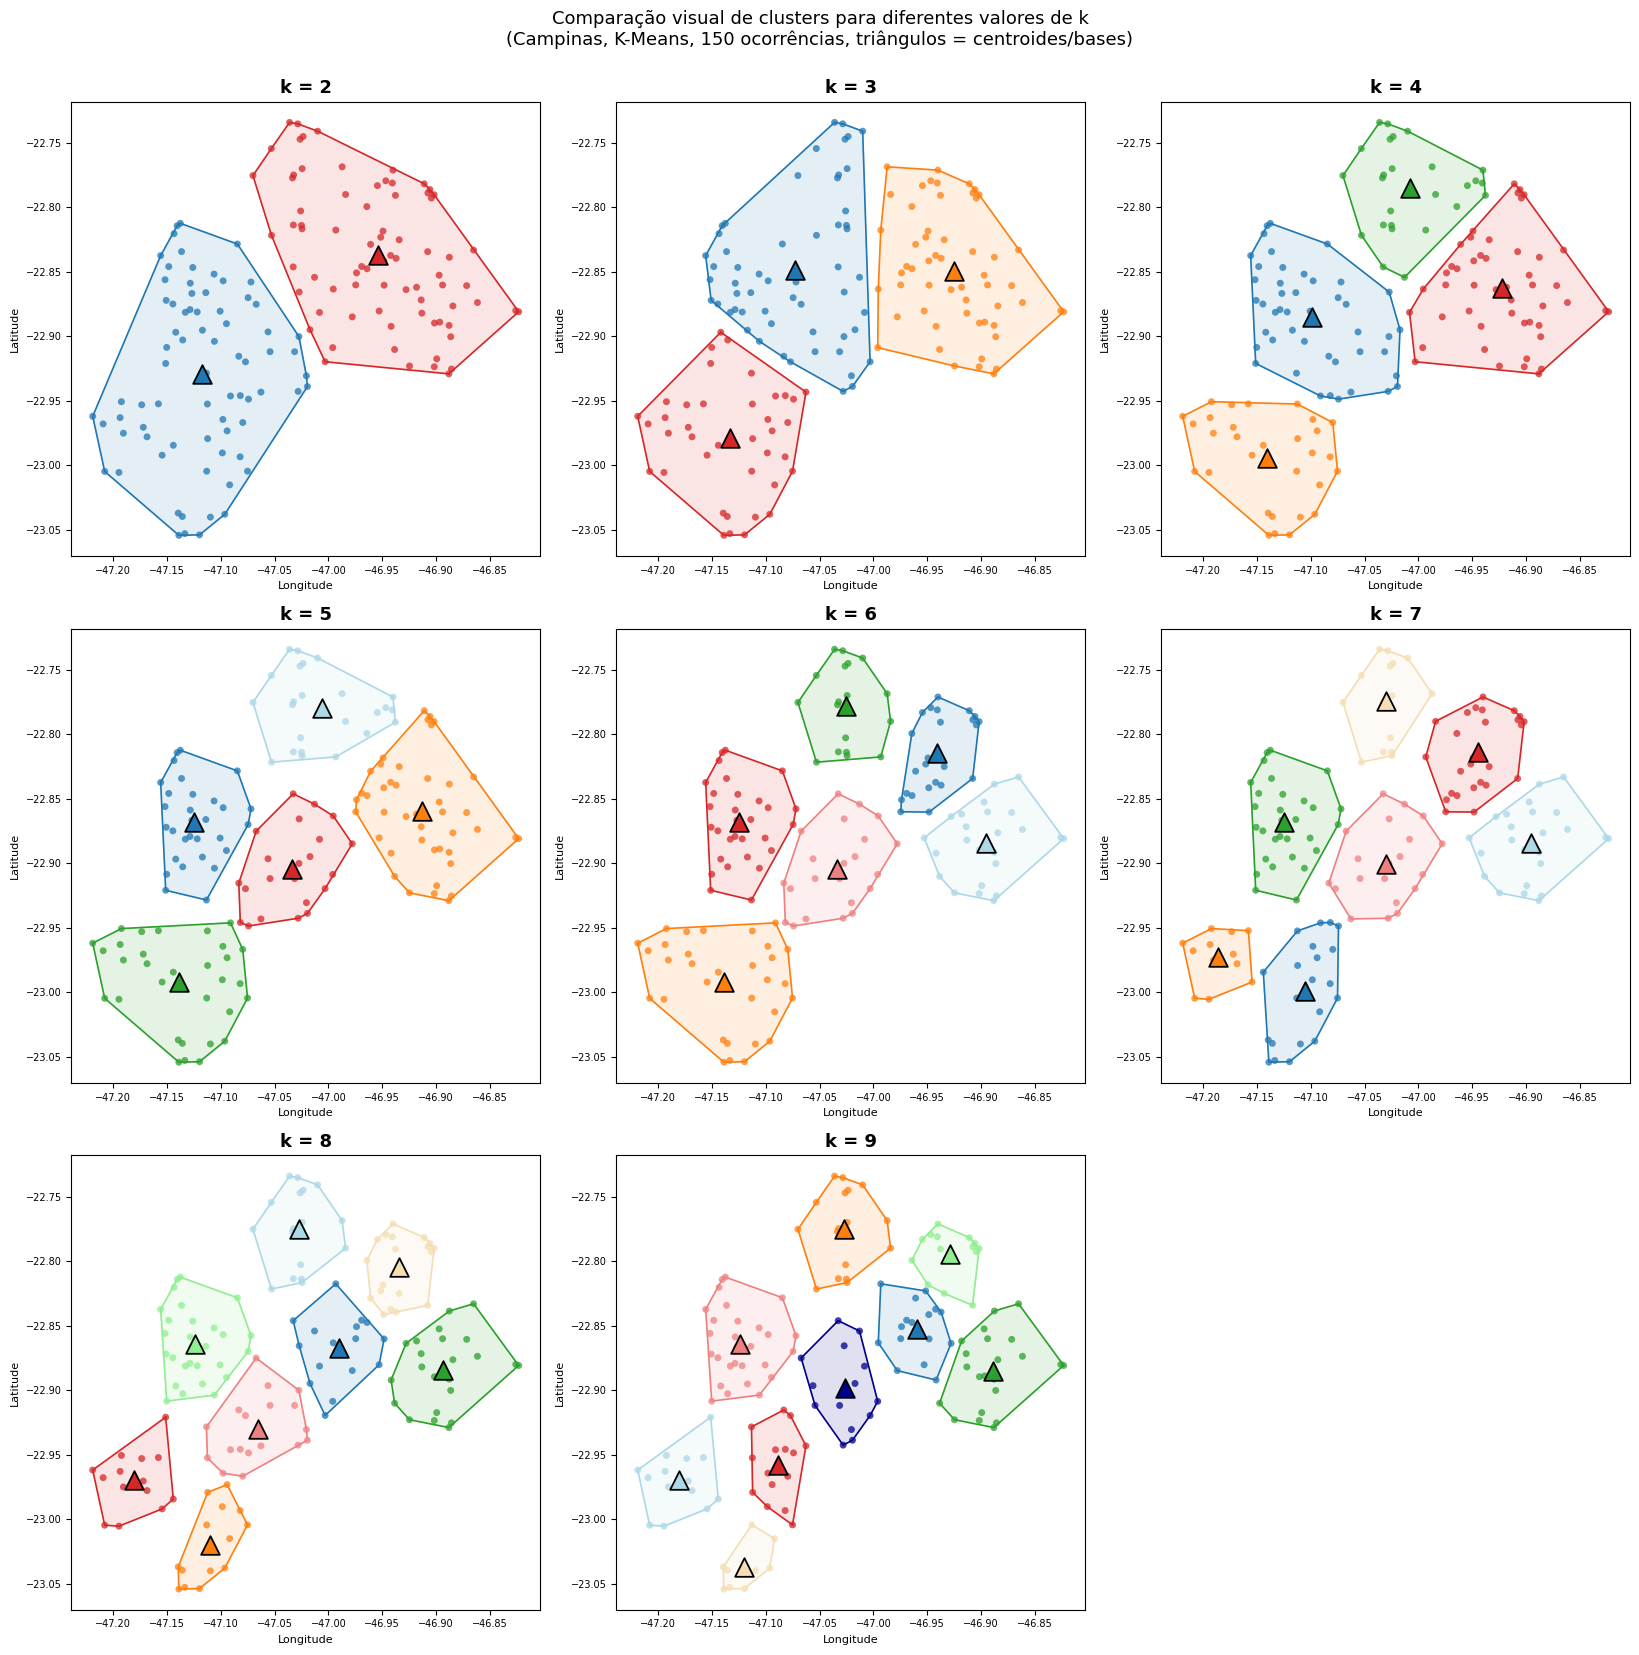


Grid de mapas salvo em: campinas_grid_mapas_k.png

[Processo iterativo] Observe visualmente: os clusters parecem compactos e geograficamente coerentes, ou muito alongados/dispersos? Algum k específico já parece claramente melhor ou pior que os vizinhos? Se quiser, ajuste K_VALUES_VISUAL (ex.: focar numa faixa menor, tipo [4,5,6,7], ou testar valores maiores) e rode esta seção de novo antes de seguir para as métricas quantitativas (Seção 4.2).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from sklearn.cluster import KMeans

# ------------------------------------------------------------------
# AJUSTE AQUI: lista de valores de k que você quer comparar visualmente.
# Sugestão inicial: uma faixa ampla, para ter uma visão geral.
# Depois de rodar uma vez, você pode reduzir/focar essa lista e rodar
# de novo (processo iterativo).
# ------------------------------------------------------------------
K_VALUES_VISUAL = [2, 3, 4, 5, 6, 7, 8, 9]

# Mesma paleta de cores usada nos mapas Folium das Seções 2.3/3.2, para
# manter consistência visual entre os mapas interativos e estes mapas
# estáticos de comparação.
CORES_MATPLOTLIB = [
    'tab:blue', 'tab:red', 'tab:orange', 'tab:green', 'lightblue',
    'lightcoral', 'wheat', 'lightgreen', 'darkblue', 'darkred',
    'pink', 'darkgreen', 'purple', 'indigo', 'cadetblue', 'gray',
]


def cor_matplotlib(cluster_id: int) -> str:
    return CORES_MATPLOTLIB[(cluster_id - 1) % len(CORES_MATPLOTLIB)]


def gerar_grid_mapas_k(df_ocorrencias: pd.DataFrame, k_values: list,
                        random_state: int = 42, n_colunas: int = 3):
    """
    Para cada valor de k em k_values:
        1. Roda o K-Means (rápido, sem OSRM)
        2. Desenha um mapa ESTÁTICO (matplotlib) com os pontos coloridos
           por cluster, o polígono de área (ConvexHull, se houver >= 3
           pontos) e um marcador '^' no centroide de cada cluster.
    Todos os mapas são organizados lado a lado num grid, para facilitar
    a comparação visual direta entre diferentes valores de k.
    """
    lat_col = 'lat' if 'lat' in df_ocorrencias.columns else 'Latitude'
    lon_col = 'lon' if 'lon' in df_ocorrencias.columns else 'Longitude'
    X = df_ocorrencias.loc[:, [lat_col, lon_col]].values

    n_k = len(k_values)
    n_linhas = int(np.ceil(n_k / n_colunas))

    fig, axes = plt.subplots(n_linhas, n_colunas,
                              figsize=(5.5 * n_colunas, 5.5 * n_linhas))
    axes = np.array(axes).reshape(-1)  # achata em 1D, mesmo se só 1 linha

    for idx, k in enumerate(k_values):
        ax = axes[idx]
        modelo = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=random_state)
        rotulos = modelo.fit_predict(X) + 1  # 1 a k, por consistência com o resto do TCC

        for cluster_id in range(1, k + 1):
            pontos_cluster = X[rotulos == cluster_id]
            cor = cor_matplotlib(cluster_id)

            ax.scatter(pontos_cluster[:, 1], pontos_cluster[:, 0],
                       color=cor, s=25, alpha=0.75, edgecolor='none')

            # Polígono de área via ConvexHull (mesmo critério de robustez
            # da Seção 2.3: exige >= 3 pontos não colineares)
            if len(pontos_cluster) >= 3:
                try:
                    hull = ConvexHull(pontos_cluster[:, [1, 0]])  # (lon, lat) p/ eixo x,y
                    hull_pts = pontos_cluster[hull.vertices]
                    ax.fill(hull_pts[:, 1], hull_pts[:, 0], color=cor, alpha=0.12)
                    ax.plot(np.append(hull_pts[:, 1], hull_pts[0, 1]),
                            np.append(hull_pts[:, 0], hull_pts[0, 0]),
                            color=cor, linewidth=1.2)
                except Exception:
                    pass  # cluster degenerado (pontos colineares) -- só pula a área

            centro = pontos_cluster.mean(axis=0)
            ax.scatter(centro[1], centro[0], color=cor, s=180, marker='^',
                       edgecolor='black', linewidth=1.3, zorder=5)

        ax.set_title(f'k = {k}', fontsize=13, fontweight='bold')
        ax.set_xlabel('Longitude', fontsize=8)
        ax.set_ylabel('Latitude', fontsize=8)
        ax.tick_params(labelsize=7)

    # Remove eixos vazios sobrando (se n_k não preencher o grid completo)
    for idx in range(n_k, len(axes)):
        fig.delaxes(axes[idx])

    plt.suptitle(f'Comparação visual de clusters para diferentes valores de k\n'
                 f'(Campinas, K-Means, {len(df_ocorrencias)} ocorrências, '
                 f'triângulos = centroides/bases)', fontsize=13, y=1.00)
    plt.tight_layout()
    return fig


print(f"Gerando grid comparativo de mapas para k = {K_VALUES_VISUAL} "
      f"(Campinas, {len(df_ocorrencias_campinas)} ocorrências)...")

fig_grid = gerar_grid_mapas_k(df_ocorrencias_campinas, K_VALUES_VISUAL, random_state=42)
fig_grid.savefig('campinas_grid_mapas_k.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nGrid de mapas salvo em: campinas_grid_mapas_k.png")
print("\n[Processo iterativo] Observe visualmente: os clusters parecem "
      "compactos e geograficamente coerentes, ou muito alongados/dispersos? "
      "Algum k específico já parece claramente melhor ou pior que os vizinhos? "
      "Se quiser, ajuste K_VALUES_VISUAL (ex.: focar numa faixa menor, tipo "
      "[4,5,6,7], ou testar valores maiores) e rode esta seção de novo antes "
      "de seguir para as métricas quantitativas (Seção 4.2).")

# 5. Cálculo dos clusters - Agglomerative Clustering para k=5

- O AgglomerativeClustering do scikit-learn NÃO calcula um centro de cluster nativamente (não existe atributo cluster_centers_, ao contrário do KMeans). Isso é coerente com a lógica hierárquica do algoritmo - o processo de fusão (linkage='ward') nunca usa a noção de "centro fixo", ele trabalha com variância entre pontos.

  - Por isso, esta seção inclui uma função auxiliar calcular_centroides_por_cluster() que calcula manualmente a média aritmética das coordenadas (Latitude, Longitude) de cada cluster após a atribuição de rótulos - exatamente a mesma definição de "base = centroide geométrico do cluster" já usada para o K-Means, só que obtida por um caminho diferente.

- k=5 mantido igual ao Passo 1 (K-Means) de propósito, para permitir uma
comparação direta e justa entre os dois métodos sobre o MESMO valor de
k e o MESMO conjunto de ocorrências (df_ocorrencias_campinas).

## 5.1. Aplicação do Agglomerative Clustering


In [ ]:
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering

MODEL_NAME_AGG = 'agglomerative'
N_CLUSTERS_AGG = 5  # mesmo k do Passo 1 (K-Means), para comparação direta
LINKAGE_AGG = 'ward'  # ver material de apoio: 'ward' é o critério recomendado
                       # para este TCC (dados sem formato não-convexo conhecido)
COLUNA_CLUSTER_AGG = f'{MODEL_NAME_AGG}{N_CLUSTERS_AGG}'


def calcular_centroides_por_cluster(df_com_cluster: pd.DataFrame,
                                     coluna_cluster: str) -> dict:
    """
    Calcula manualmente o centroide (média aritmética de Latitude e
    Longitude) de cada cluster -- necessário porque o
    AgglomerativeClustering, ao contrário do KMeans, não fornece esse
    valor nativamente (sem atributo cluster_centers_).

    Retorna um dicionário no MESMO formato usado pelo KMeans no Passo 1
    (centers_dict = {'1': [lat, lon], '2': [lat, lon], ...}), para que
    as funções de mapa já existentes (create_map, create_polygons etc.)
    possam ser reaproveitadas sem nenhuma alteração.
    """
    centers_dict = {}
    for cluster_id in sorted(df_com_cluster[coluna_cluster].unique()):
        pontos_cluster = df_com_cluster[
            df_com_cluster[coluna_cluster] == cluster_id
        ][['Latitude', 'Longitude']]
        centro_lat = pontos_cluster['Latitude'].mean()
        centro_lon = pontos_cluster['Longitude'].mean()
        centers_dict[str(int(cluster_id))] = np.array([centro_lat, centro_lon])
    return centers_dict


def aplicar_agglomerative(df_ocorrencias: pd.DataFrame, n_clusters: int,
                           coluna_cluster: str, linkage: str = 'ward'):
    """
    Aplica o Agglomerative Clustering sobre as coordenadas (lat, lon)
    das ocorrências.

    Retorna:
        df_com_cluster : cópia do DataFrame de entrada, com colunas
                          novas: 'Latitude'/'Longitude' (renomeadas de
                          lat/lon) e o rótulo do cluster (na coluna
                          indicada por 'coluna_cluster', numerado a
                          partir de 1 -- mesma convenção do K-Means).
        centers_dict    : dicionário {'1': [lat, lon], '2': [lat, lon], ...}
                          com o centroide de cada cluster, calculado
                          manualmente (ver calcular_centroides_por_cluster).
                          É este centroide que representa a base de
                          ambulância alocada para aquele grupo.

    Nota: diferente do KMeans, o AgglomerativeClustering não aceita
    random_state -- o algoritmo é DETERMINÍSTICO (sempre produz o mesmo
    resultado para os mesmos dados e mesmo linkage), então não há
    necessidade de fixar uma semente aqui.
    """
    df_com_cluster = df_ocorrencias.rename(
        columns={'lat': 'Latitude', 'lon': 'Longitude'}
    ).copy()

    X = df_com_cluster.loc[:, ['Latitude', 'Longitude']].values

    modelo = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage=linkage,
    )
    rotulos = modelo.fit_predict(X)

    df_com_cluster[coluna_cluster] = rotulos + 1

    centers_dict = calcular_centroides_por_cluster(df_com_cluster, coluna_cluster)

    return df_com_cluster, centers_dict


df_accidents_agg, centers_dict_agg = aplicar_agglomerative(
    df_ocorrencias_campinas,
    n_clusters=N_CLUSTERS_AGG,
    coluna_cluster=COLUNA_CLUSTER_AGG,
    linkage=LINKAGE_AGG,
)

print(f"Agglomerative Clustering aplicado com k={N_CLUSTERS_AGG}, "
      f"linkage='{LINKAGE_AGG}' (Campinas)")
print(f"Coluna de cluster criada: '{COLUNA_CLUSTER_AGG}'")
print("\nCentros dos clusters (base de ambulância = centroide, calculado manualmente):")
for cluster_id, centro in centers_dict_agg.items():
    print(f"  Cluster {cluster_id}: lat={centro[0]:.5f}, lon={centro[1]:.5f}")

print("\nQuantidade de ocorrências por cluster:")
print(df_accidents_agg[COLUNA_CLUSTER_AGG].value_counts().sort_index())

print("\nAmostra da tabela com o cluster atribuído:")
try:
    display(df_accidents_agg.head())
except NameError:
    print(df_accidents_agg.head())

Agglomerative Clustering aplicado com k=5, linkage='ward' (Campinas)
Coluna de cluster criada: 'agglomerative5'

Centros dos clusters (base de ambulância = centroide, calculado manualmente):
  Cluster 1: lat=-22.84910, lon=-46.92433
  Cluster 2: lat=-22.99875, lon=-47.16272
  Cluster 3: lat=-22.80583, lon=-47.04272
  Cluster 4: lat=-22.94621, lon=-47.06651
  Cluster 5: lat=-22.86858, lon=-47.13285

Quantidade de ocorrências por cluster:
agglomerative5
1    54
2    20
3    25
4    27
5    24
Name: count, dtype: int64

Amostra da tabela com o cluster atribuído:


,ID,Latitude,Longitude,T1,T2,T4,T5,municipio_nome,Populacao_2022,agglomerative5
0,Campinas-0000,-22.911902,-47.031435,2.346340,1.444060,10.956707,11.467542,Campinas,1139047,4
1,Campinas-0001,-22.799347,-46.964275,6.156250,2.505258,8.591577,13.082560,Campinas,1139047,1
2,Campinas-0002,-22.821638,-47.052959,1.003395,1.714310,7.227751,2.701279,Campinas,1139047,3
3,Campinas-0003,-22.920985,-47.151356,1.721115,2.475185,6.961507,11.671193,Campinas,1139047,5
4,Campinas-0004,-22.896533,-47.056185,1.727578,1.648328,3.581138,7.280959,Campinas,1139047,4


## 5.2. Tempo total do serviço

In [ ]:
df_accidents_agg['Total_Time'] = (
    df_accidents_agg['T1'] + df_accidents_agg['T2']
    + df_accidents_agg['T4'] + df_accidents_agg['T5']
)

print("\nTempo total (T1+T2+T4+T5, SEM T3 ainda) por ocorrência:")
try:
    display(df_accidents_agg[['ID', COLUNA_CLUSTER_AGG, 'Total_Time']].head())
except NameError:
    print(df_accidents_agg[['ID', COLUNA_CLUSTER_AGG, 'Total_Time']].head())

print("\nTempo total médio por cluster (minutos):")
print(df_accidents_agg.groupby(COLUNA_CLUSTER_AGG)['Total_Time'].mean().round(2))



Tempo total (T1+T2+T4+T5, SEM T3 ainda) por ocorrência:


,ID,agglomerative5,Total_Time
0,Campinas-0000,4,26.214649
1,Campinas-0001,1,30.335644
2,Campinas-0002,3,12.646736
3,Campinas-0003,5,22.828999
4,Campinas-0004,4,14.238002



Tempo total médio por cluster (minutos):
agglomerative5
1    28.29
2    28.92
3    27.03
4    29.90
5    27.16
Name: Total_Time, dtype: float64


## 5.3. Visualização em um mapa dos clusters encontrados



In [ ]:
import folium

map_osm_agg = create_map(df_accidents_agg)
map_osm_agg = draw_points_clustered(map_osm_agg, df_accidents_agg, COLUNA_CLUSTER_AGG)
map_osm_agg = create_polygons(map_osm_agg, df_accidents_agg, COLUNA_CLUSTER_AGG, centers_dict_agg)
map_osm_agg.add_child(folium.LayerControl(collapsed=False, position='bottomright'))
map_osm_agg.save(f'campinas_mapa_{COLUNA_CLUSTER_AGG}.html')
print(f"Mapa interativo salvo em: campinas_mapa_{COLUNA_CLUSTER_AGG}.html")

map_osm_agg  # no Colab, isso renderiza o mapa interativo diretamente na célula

Mapa interativo salvo em: campinas_mapa_agglomerative5.html


# 6. Cálculo detalhado para Agglomerative Clustering, k=5

## 6.1. Cálculo da distância via OSRM (rota real de carro)

In [ ]:
import time
import math
import numpy as np
import pandas as pd
import folium
import polyline
import requests
from scipy import stats

print("Calculando rotas via OSRM (isso pode levar alguns minutos, "
      "dependendo da quantidade de ocorrências)...")
vD_log_agg, vD_route_agg = get_dist_paths_centers(
    df_accidents_agg, COLUNA_CLUSTER_AGG, centers_dict_agg
)

# Total de falhas (NaN) para você monitorar a qualidade da coleta
total_falhas_agg = sum(
    sum(1 for d in distancias if pd.isna(d))
    for distancias in vD_log_agg.values()
)
if total_falhas_agg > 0:
    print(f"[Aviso] {total_falhas_agg} rota(s) não puderam ser calculadas "
          f"pelo OSRM e ficaram como NaN.")

total_distance_agg = get_total_distance(vD_log_agg)   # função definida na Seção 3.1
print('Total distance (Agglomerative) = ', total_distance_agg)

# ==========================================================
# Atribuir a distância de volta ao df_accidents_agg (uma linha por ocorrência)
# e calcular T3 (tempo de deslocamento) e o Total_Time
# ==========================================================
df_accidents_agg['Distancia_km'] = np.nan
for cluster_id_str, distancias in vD_log_agg.items():
    cluster_id = int(cluster_id_str)
    idx = df_accidents_agg[df_accidents_agg[COLUNA_CLUSTER_AGG] == cluster_id].index
    df_accidents_agg.loc[idx, 'Distancia_km'] = distancias

# T3 = tempo de deslocamento (minutos), estimado a partir da distância real (OSRM) e da velocidade média assumida.
df_accidents_agg['T3'] = (df_accidents_agg['Distancia_km'] / VELOCIDADE_MEDIA_KMH) * 60

# Total_Time: inclui T3
df_accidents_agg['Total_Time'] = (
    df_accidents_agg['T1'] + df_accidents_agg['T2'] + df_accidents_agg['T3']
    + df_accidents_agg['T4'] + df_accidents_agg['T5']
)

print("\nAmostra com distância, T3 e Total_Time corrigido:")
colunas_mostrar_agg = ['ID', COLUNA_CLUSTER_AGG, 'Distancia_km', 'T3', 'Total_Time']
try:
    display(df_accidents_agg[colunas_mostrar_agg].head())
except NameError:
    print(df_accidents_agg[colunas_mostrar_agg].head())

Calculando rotas via OSRM (isso pode levar alguns minutos, dependendo da quantidade de ocorrências)...
Total distance (Agglomerative) =  1552.4515999999999

Amostra com distância, T3 e Total_Time corrigido:


,ID,agglomerative5,Distancia_km,T3,Total_Time
0,Campinas-0000,4,9.2381,13.85715,40.071799
1,Campinas-0001,1,11.6611,17.49165,47.827294
2,Campinas-0002,3,3.3843,5.07645,17.723186
3,Campinas-0003,5,14.0266,21.03990,43.868899
4,Campinas-0004,4,11.3844,17.07660,31.314602


## 6.2. Mapa das rotas entre os centros dos clusters e as ocorrências

In [ ]:
dist_map_osm_agg = get_route_map(df_accidents_agg, COLUNA_CLUSTER_AGG, centers_dict_agg, vD_route_agg)

dist_map_osm_agg.save(f"campinas_mapa_rotas_{COLUNA_CLUSTER_AGG}.html")

print(f"\nMapa de rotas salvo em: "f"campinas_mapa_rotas_{COLUNA_CLUSTER_AGG}.html")

dist_map_osm_agg


Mapa de rotas salvo em: campinas_mapa_rotas_agglomerative5.html


## 6.3. Relatório de tempos médios e máximos por cluster


In [ ]:
report_df_agg = df_accidents_agg.groupby(COLUNA_CLUSTER_AGG)[
    ['T1', 'T2', 'T3', 'T4', 'T5', 'Total_Time']
].agg(['mean', 'max'])
report_df_agg.columns = ['_'.join(col).strip() for col in report_df_agg.columns.values]

print("\nRelatório de tempos médios e máximos por cluster (minutos):")
try:
    display(report_df_agg)
except NameError:
    print(report_df_agg)


Relatório de tempos médios e máximos por cluster (minutos):


,T1_mean,T1_max,T2_mean,T2_max,T3_mean,T3_max,T4_mean,T4_max,T5_mean,T5_max,Total_Time_mean,Total_Time_max
agglomerative5,,,,,,,,,,,,
1,5.075690,20.193211,2.002631,3.194518,17.379125,44.42925,10.606635,17.617488,10.600684,21.680861,45.664764,66.391032
2,4.833598,18.617785,2.074195,2.853302,13.948380,21.62865,10.684220,16.142197,11.329738,20.464223,42.870131,55.978232
3,4.999652,40.862228,2.070536,2.685931,17.119434,25.68510,9.333896,14.152047,10.629958,31.120932,44.153475,83.412386
4,4.933360,14.984862,1.909972,2.521246,15.187011,48.99405,9.703384,19.236642,13.350067,38.864630,45.083794,79.191680
5,3.181603,11.787881,2.067117,2.830651,11.383413,32.92650,10.421555,16.182244,11.489554,24.921463,38.543241,85.434026


## 6.4. Distância média e máxima do centro do cluster aos pontos de demanda

In [ ]:
distance_stats_agg = {}
for cluster_id, distancias in vD_log_agg.items():
    distancias_validas = [d for d in distancias if not pd.isna(d)]
    if distancias_validas:
        distance_stats_agg[cluster_id] = {
            'mean_distance_km': np.mean(distancias_validas),
            'max_distance_km': np.max(distancias_validas),
        }
    else:
        distance_stats_agg[cluster_id] = {'mean_distance_km': np.nan, 'max_distance_km': np.nan}

df_distance_stats_agg = pd.DataFrame.from_dict(distance_stats_agg, orient='index')
df_distance_stats_agg.index.name = 'Cluster'

print("\nDistância média e máxima por cluster (km):")
try:
    display(df_distance_stats_agg)
except NameError:
    print(df_distance_stats_agg)


Distância média e máxima por cluster (km):


,mean_distance_km,max_distance_km
Cluster,,
1,11.586083,29.6195
2,9.298920,14.4191
3,11.412956,17.1234
4,10.124674,32.6627
5,7.588942,21.9510


## 6.5. Intervalos de confiança (95%) para Tempo Total e Distância

### 6.5.1. Intervalos de Confiança para o Tempo Total (T1 + T2 + T3 + T4 + T5) por Cluster

In [ ]:
total_time_cis_agg = {}
for cluster_id in np.sort(df_accidents_agg[COLUNA_CLUSTER_AGG].unique()):
    dados = df_accidents_agg[
        df_accidents_agg[COLUNA_CLUSTER_AGG] == cluster_id
    ]['Total_Time'].values
    lower, upper = calculate_confidence_interval(dados)
    total_time_cis_agg[cluster_id] = {
        'Total_Time_mean_CI_lower': lower,
        'Total_Time_mean_CI_upper': upper,
    }

df_total_time_cis_agg = pd.DataFrame.from_dict(total_time_cis_agg, orient='index')
df_total_time_cis_agg.index.name = 'Cluster'

print("\nIntervalo de Confiança de 95% para o Tempo Total, por cluster:")
try:
    display(df_total_time_cis_agg)
except NameError:
    print(df_total_time_cis_agg)

all_total_time_agg = df_accidents_agg['Total_Time'].values
lower_geral_agg, upper_geral_agg = calculate_confidence_interval(all_total_time_agg)
print(f"\nIntervalo de Confiança de 95% para o Tempo Total (Campinas, geral): "
      f"({lower_geral_agg:.2f}, {upper_geral_agg:.2f}) minutos")


Intervalo de Confiança de 95% para o Tempo Total, por cluster:


,Total_Time_mean_CI_lower,Total_Time_mean_CI_upper
Cluster,,
1,43.154206,48.175323
2,39.149638,46.590624
3,38.856611,49.450340
4,40.437687,49.729901
5,33.198011,43.888470



Intervalo de Confiança de 95% para o Tempo Total (Campinas, geral): (42.03, 45.56) minutos


### 6.5.2. Intervalos de Confiança para Distância Percorrida por Cluster e Total


In [ ]:
distance_cis_agg = {}
for cluster_id_str, distancias in vD_log_agg.items():
    lower, upper = calculate_confidence_interval(distancias)
    distance_cis_agg[cluster_id_str] = {
        'Distance_mean_CI_lower': lower,
        'Distance_mean_CI_upper': upper,
    }

df_distance_cis_agg = pd.DataFrame.from_dict(distance_cis_agg, orient='index')
df_distance_cis_agg.index.name = 'Cluster'

print("\nIntervalo de Confiança de 95% para a Distância, por cluster (km):")
try:
    display(df_distance_cis_agg)
except NameError:
    print(df_distance_cis_agg)

all_distances_agg = []
for distancias in vD_log_agg.values():
    all_distances_agg.extend(distancias)
lower_dist_agg, upper_dist_agg = calculate_confidence_interval(all_distances_agg)
print(f"\nIntervalo de Confiança de 95% para a Distância Total (Campinas, geral): "
      f"({lower_dist_agg:.2f}, {upper_dist_agg:.2f}) km")


Intervalo de Confiança de 95% para a Distância, por cluster (km):


,Distance_mean_CI_lower,Distance_mean_CI_upper
Cluster,,
1,10.092807,13.079360
2,7.506787,11.091053
3,9.833711,12.992201
4,7.974330,12.275018
5,5.294713,9.883171



Intervalo de Confiança de 95% para a Distância Total (Campinas, geral): (9.52, 11.18) km


# 7. Otimização de hiperparâmetros com Optuna (Silhouette) e avaliação operacional (OSRM)

Estrutura metodológica desta seção:
1. DOIS ESTUDOS OPTUNA INDEPENDENTES, um por método, sobre a MESMA matriz de
   coordenadas (as 150 ocorrências de Campinas), cada um com o seu espaço de busca:
   - K-Means:        n_clusters (2 a 9) x init ('k-means++', 'random') x n_init (5, 10, 20)
     = 48 configurações; random_state fixo.
   - Agglomerative:  n_clusters (2 a 9) x linkage ('ward', 'complete', 'average', 'single')
     x metric ('euclidean', 'manhattan'), com a restrição de que 'ward'
     só aceita 'euclidean' = 8 + 8 x 3 x 2 = 56 configurações.
2. OBJETIVO DOS ESTUDOS: maximizar o Silhouette Score (sempre com distância
   euclidiana, para que os dois métodos sejam comparáveis). Amostrador:
   TPESampler(seed=42), para tornar a busca reprodutível.
3. BUSCA PARCIAL: o número de trials é menor que o espaço de busca (ver a tabela de
   cobertura) e o TPE pode repetir configurações. Logo, a busca NÃO é exaustiva e o
   resultado é "a melhor configuração encontrada", não "o máximo global garantido".
4. COMPARAÇÃO POR MÉTODO: o melhor K-Means é comparado ao baseline K-Means, e o
   melhor Agglomerative é comparado ao baseline Agglomerative.
5. CONFIGURAÇÃO GERAL: entre os dois melhores trials, o maior Silhouette Score define
   a configuração geral da otimização.
6. AVALIAÇÃO OPERACIONAL: após os estudos, o OSRM avalia quatro cenários: baseline
   K-Means (k=5, init='k-means++', n_init=10), baseline Agglomerative (k=5,
   linkage='ward', métrica euclidiana), melhor K-Means e melhor Agglomerative. Os
   resultados são reunidos em uma tabela. A configuração geral é uma das duas
   configurações otimizadas e não representa necessariamente a melhor opção operacional.
Optuna + Silhouette  ->  qualidade interna (geométrica) dos agrupamentos
OSRM + T3            ->  deslocamento na rede viária

## 7.1. Configuração

In [ ]:
!pip install optuna

import numpy as np
import pandas as pd
import optuna
from optuna.samplers import TPESampler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Mostra só avisos do Optuna (deixa a saída das células mais limpa)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ==========================================================================
# Parâmetros dos estudos (AJUSTE AQUI)
# ==========================================================================
SEED_OPTUNA = 42       # semente do TPESampler (reprodutibilidade da busca)
N_TRIALS_KMEANS = 20      # trials do estudo do K-Means
N_TRIALS_AGG = 20         # trials do estudo do Agglomerative

K_MIN_OPT = 2             # menor k testado
K_MAX_OPT = 9             # maior k testado (mesma faixa da Seção 4)

# Opções de hiperparâmetros
INIT_OPT = ['k-means++', 'random']
N_INIT_OPT = [5, 10, 20]
LINKAGE_OPT = ['ward', 'complete', 'average', 'single']
METRICA_OPT = ['euclidean', 'manhattan']   # usada só quando linkage != 'ward'

# Baseline: a configuração da Seção 2 (K-Means, k=5, k-means++, n_init=10)
BASELINE_K = 5
BASELINE_INIT = 'k-means++'
BASELINE_N_INIT = 10

# Baseline: a configuração da Seção 4 (Agglomerative, k=5, critério de ward)
BASELINE_LINKAGE_AGG = 'ward'
BASELINE_METRIC_AGG = 'euclidean'

print("Estudo K-Means      :", f"n_clusters {K_MIN_OPT}-{K_MAX_OPT}, init {INIT_OPT}, "
      f"n_init {N_INIT_OPT}, random_state={RANDOM_STATE} (fixo), {N_TRIALS_KMEANS} trials")
print("Estudo Agglomerative:", f"n_clusters {K_MIN_OPT}-{K_MAX_OPT}, linkage {LINKAGE_OPT}, "
      f"metric {METRICA_OPT} (ward: só euclidean), {N_TRIALS_AGG} trials")
print(f"Sampler: TPESampler(seed={SEED_OPTUNA}) | objetivo: maximizar o Silhouette Score")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]
Estudo K-Means      : n_clusters 2-9, init ['k-means++', 'random'], n_init [5, 10, 20], random_state=42 (fixo), 20 trials
Estudo Agglomerative: n_clusters 2-9, linkage ['ward', 'complete', 'average', 'single'], metric ['euclidean', 'manhattan'] (ward: só euclidean), 20 trials
Sampler: TPESampler(seed=42) | objetivo: maximizar o Silhouette Score


## 7.2. Funções de apoio: aplicar a configuração e calcular o Silhouette

In [ ]:
"""
As funções abaixo seguem o mesmo padrão de aplicar_kmeans() (Seção 2) e de
aplicar_agglomerative() (Seção 5), mas recebem os hiperparâmetros que o Optuna vai
testar. Com os valores da Seção 2 (init='k-means++', n_init=10, random_state=42), o
resultado do K-Means é idêntico ao de aplicar_kmeans().

O Silhouette é SEMPRE calculado com a distância euclidiana (padrão do scikit-learn)
sobre as coordenadas (Latitude, Longitude), para que os dois métodos sejam comparados
com a mesma régua, mesmo quando o Agglomerative agrupa com a métrica 'manhattan'.
"""


def aplicar_kmeans_opt(df_ocorrencias: pd.DataFrame, n_clusters: int,
                       coluna_cluster: str, init: str = 'k-means++',
                       n_init: int = 10, random_state: int = 42):
    """
    Aplica o K-Means com os hiperparâmetros informados.
    Retorna (df_com_cluster, centers_dict), no mesmo formato de aplicar_kmeans().
    """
    df_com_cluster = df_ocorrencias.rename(
        columns={'lat': 'Latitude', 'lon': 'Longitude'}
    ).copy()
    X = df_com_cluster.loc[:, ['Latitude', 'Longitude']].values
    modelo = KMeans(
        n_clusters=n_clusters,
        init=init,
        n_init=n_init,
        random_state=random_state,
    )
    rotulos = modelo.fit_predict(X)
    df_com_cluster[coluna_cluster] = rotulos + 1
    centers_dict = {
        str(i + 1): modelo.cluster_centers_[i]
        for i in range(n_clusters)
    }
    return df_com_cluster, centers_dict


def aplicar_agglomerative_opt(df_ocorrencias: pd.DataFrame, n_clusters: int,
                              coluna_cluster: str, linkage: str = 'ward',
                              metric: str = 'euclidean'):
    """
    Aplica o Agglomerative Clustering com linkage e métrica informados.
    Retorna (df_com_cluster, centers_dict), no mesmo formato de aplicar_agglomerative().
    O centroide é a média das coordenadas de cada cluster (Seção 5).
    """
    df_com_cluster = df_ocorrencias.rename(
        columns={'lat': 'Latitude', 'lon': 'Longitude'}
    ).copy()
    X = df_com_cluster.loc[:, ['Latitude', 'Longitude']].values
    modelo = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage=linkage,
        metric=metric,
    )
    rotulos = modelo.fit_predict(X)
    df_com_cluster[coluna_cluster] = rotulos + 1
    centers_dict = calcular_centroides_por_cluster(df_com_cluster, coluna_cluster)
    return df_com_cluster, centers_dict


def calcular_silhouette(df_com_cluster: pd.DataFrame, coluna_cluster: str) -> float:
    """
    Silhouette Score (distância euclidiana) sobre TODAS as ocorrências.
    Devolve -1.0 se houver menos de 2 clusters (configuração inválida).
    """
    X = df_com_cluster.loc[:, ['Latitude', 'Longitude']].values
    rotulos = df_com_cluster[coluna_cluster].values
    if len(np.unique(rotulos)) < 2:
        return -1.0
    return float(silhouette_score(X, rotulos))

## 7.3. Funções objetivo (uma por método)

In [ ]:
"""

Cada função recebe um trial, sorteia os hiperparâmetros daquele método, aplica a
clusterização e devolve o Silhouette Score (que o Optuna vai MAXIMIZAR). O espaço de
busca do Agglomerative é condicional: com linkage='ward', a métrica não é sorteada e
fica fixa em 'euclidean'.
"""


def objective_kmeans(trial: optuna.Trial) -> float:
    k = trial.suggest_int('n_clusters', K_MIN_OPT, K_MAX_OPT)
    init = trial.suggest_categorical('init', INIT_OPT)
    n_init = trial.suggest_categorical('n_init', N_INIT_OPT)

    coluna = f'kmeans{k}'
    df_cl, _ = aplicar_kmeans_opt(df_ocorrencias_campinas, n_clusters=k,
                                  coluna_cluster=coluna, init=init, n_init=n_init,
                                  random_state=RANDOM_STATE)
    return calcular_silhouette(df_cl, coluna)


def objective_agglomerative(trial: optuna.Trial) -> float:
    k = trial.suggest_int('n_clusters', K_MIN_OPT, K_MAX_OPT)
    linkage = trial.suggest_categorical('linkage', LINKAGE_OPT)
    if linkage == 'ward':
        metric = 'euclidean'          # Ward só aceita a métrica euclidiana (não é sorteada)
    else:
        metric = trial.suggest_categorical('metric', METRICA_OPT)
    trial.set_user_attr('metric', metric)   # guarda a métrica usada (inclusive no Ward)

    coluna = f'agglomerative{k}'
    df_cl, _ = aplicar_agglomerative_opt(df_ocorrencias_campinas, n_clusters=k,
                                         coluna_cluster=coluna, linkage=linkage,
                                         metric=metric)
    return calcular_silhouette(df_cl, coluna)

## 7.4. Estudo do K-Means

In [ ]:

"""
O TPESampler sorteia os primeiros trials ao acaso (10, por padrão) e passa a usar os
resultados anteriores para escolher os seguintes.
"""

study_kmeans = optuna.create_study(
    study_name='kmeans_silhouette',
    direction='maximize',
    sampler=TPESampler(seed=SEED_OPTUNA),
)
study_kmeans.optimize(objective_kmeans, n_trials=N_TRIALS_KMEANS)

print(f"Estudo do K-Means concluído: {len(study_kmeans.trials)} trials.")
print(f"Maior Silhouette encontrado: {study_kmeans.best_value:.4f}")
print(f"Hiperparâmetros (best_trial do Optuna): {study_kmeans.best_params}")

Estudo do K-Means concluído: 20 trials.
Maior Silhouette encontrado: 0.4991
Hiperparâmetros (best_trial do Optuna): {'n_clusters': 2, 'init': 'k-means++', 'n_init': 20}


## 7.5. Estudo do Agglomerative Clustering

In [ ]:
study_agglomerative = optuna.create_study(
    study_name='agglomerative_silhouette',
    direction='maximize',
    sampler=TPESampler(seed=SEED_OPTUNA),
)
study_agglomerative.optimize(objective_agglomerative, n_trials=N_TRIALS_AGG)

print(f"Estudo do Agglomerative concluído: {len(study_agglomerative.trials)} trials.")
print(f"Maior Silhouette encontrado: {study_agglomerative.best_value:.4f}")
print(f"Hiperparâmetros (best_trial do Optuna): {study_agglomerative.best_params}")

Estudo do Agglomerative concluído: 20 trials.
Maior Silhouette encontrado: 0.4851
Hiperparâmetros (best_trial do Optuna): {'n_clusters': 2, 'linkage': 'average', 'metric': 'manhattan'}


## 7.6. Tabelas dos trials e melhor configuração de cada método

In [ ]:
"""
Critério de desempate: se mais de um trial atingir o mesmo Silhouette máximo (o que
pode acontecer, pois hiperparâmetros diferentes podem gerar a mesma partição), escolhe-se,
pela ordem: o menor k; depois, a configuração mais próxima da usada nas seções anteriores
(K-Means: init='k-means++' e n_init=10; Agglomerative: linkage='ward' e metric='euclidean');
por fim, o trial de menor número.
"""


def tabela_trials(estudo: optuna.Study, metodo: str) -> pd.DataFrame:
    """Uma linha por trial concluído, ordenada do maior para o menor Silhouette."""
    linhas = []
    for t in estudo.trials:
        if t.state != optuna.trial.TrialState.COMPLETE:
            continue
        if metodo == 'kmeans':
            linhas.append({'trial': t.number, 'k': t.params['n_clusters'],
                           'init': t.params['init'], 'n_init': t.params['n_init'],
                           'silhouette': t.value})
        else:
            linhas.append({'trial': t.number, 'k': t.params['n_clusters'],
                           'linkage': t.params['linkage'],
                           'metric': t.user_attrs['metric'],
                           'silhouette': t.value})
    return (pd.DataFrame(linhas)
            .sort_values(['silhouette', 'trial'], ascending=[False, True])
            .reset_index(drop=True))


def selecionar_melhor_trial(estudo: optuna.Study, metodo: str):
    """
    Devolve (melhor_trial, n_empatados): o trial de maior Silhouette, aplicando o
    critério de desempate descrito acima.
    """
    completos = [t for t in estudo.trials if t.state == optuna.trial.TrialState.COMPLETE]
    maior = max(t.value for t in completos)
    empatados = [t for t in completos if maior - t.value < 1e-9]

    def chave(t):
        if metodo == 'kmeans':
            return (t.params['n_clusters'], t.params['init'] != 'k-means++',
                    abs(t.params['n_init'] - 10), t.number)
        return (t.params['n_clusters'], t.params['linkage'] != 'ward',
                t.user_attrs['metric'] != 'euclidean', t.number)

    return sorted(empatados, key=chave)[0], len(empatados)


def hiperparametros_do_trial(trial: optuna.trial.FrozenTrial, metodo: str) -> dict:
    """Hiperparâmetros completos do trial (inclui a métrica do Ward)."""
    hp = {'n_clusters': trial.params['n_clusters']}
    if metodo == 'kmeans':
        hp.update({'init': trial.params['init'], 'n_init': trial.params['n_init']})
    else:
        hp.update({'linkage': trial.params['linkage'],
                   'metric': trial.user_attrs['metric']})
    return hp


def descrever_hiperparametros(metodo: str, hp: dict) -> str:
    if metodo == 'kmeans':
        return f"k={hp['n_clusters']}, init={hp['init']}, n_init={hp['n_init']}"
    return f"k={hp['n_clusters']}, linkage={hp['linkage']}, metric={hp['metric']}"


tab_kmeans = tabela_trials(study_kmeans, 'kmeans')
tab_agg = tabela_trials(study_agglomerative, 'agglomerative')

print("Trials do K-Means (ordenados pelo Silhouette):")
try:
    display(tab_kmeans.round(4))
except NameError:
    print(tab_kmeans.round(4))

print("\nTrials do Agglomerative (ordenados pelo Silhouette):")
try:
    display(tab_agg.round(4))
except NameError:
    print(tab_agg.round(4))

trial_kmeans, n_emp_kmeans = selecionar_melhor_trial(study_kmeans, 'kmeans')
trial_agg, n_emp_agg = selecionar_melhor_trial(study_agglomerative, 'agglomerative')
hp_kmeans = hiperparametros_do_trial(trial_kmeans, 'kmeans')
hp_agg = hiperparametros_do_trial(trial_agg, 'agglomerative')

# Quantas configurações DIFERENTES o TPE realmente testou (ele pode repetir configurações)
dist_kmeans = len({tuple(sorted(t.params.items())) for t in study_kmeans.trials})
dist_agg = len({tuple(sorted(t.params.items())) for t in study_agglomerative.trials})
print(f"\nConfigurações distintas testadas: K-Means {dist_kmeans} de {N_TRIALS_KMEANS} trials | "
      f"Agglomerative {dist_agg} de {N_TRIALS_AGG} trials.")

print(f"\nMelhor K-Means      : {descrever_hiperparametros('kmeans', hp_kmeans)} "
      f"| Silhouette = {trial_kmeans.value:.4f} "
      f"({n_emp_kmeans} trial(s) com este valor)")
print(f"Melhor Agglomerative: {descrever_hiperparametros('agglomerative', hp_agg)} "
      f"| Silhouette = {trial_agg.value:.4f} "
      f"({n_emp_agg} trial(s) com este valor)")

# Se houve empate, o best_params do Optuna (primeiro trial com o valor máximo) pode
# diferir do escolhido pelo critério de desempate acima; neste caso, os hiperparâmetros
# empatados produzem o mesmo Silhouette (normalmente, a mesma partição).
if n_emp_kmeans > 1 and study_kmeans.best_params != {k: v for k, v in hp_kmeans.items()}:
    print(f"Obs.: no K-Means, o best_trial do Optuna é {study_kmeans.best_params}; "
          f"o critério de desempate escolheu {hp_kmeans}.")
if n_emp_agg > 1 and study_agglomerative.best_params != {k: v for k, v in hp_agg.items() if k in study_agglomerative.best_params}:
    print(f"Obs.: no Agglomerative, o best_trial do Optuna é {study_agglomerative.best_params}; "
          f"o critério de desempate escolheu {hp_agg}.")

Trials do K-Means (ordenados pelo Silhouette):


,trial,k,init,n_init,silhouette
0,1,2,k-means++,20,0.4991
1,7,2,k-means++,5,0.4991
2,10,2,k-means++,20,0.4991
3,11,2,random,5,0.4991
4,13,2,k-means++,5,0.4991
5,18,2,random,20,0.4991
6,2,8,k-means++,20,0.4481
7,8,6,random,10,0.4355
8,5,6,k-means++,10,0.4336
9,9,6,k-means++,20,0.4335



Trials do Agglomerative (ordenados pelo Silhouette):


,trial,k,linkage,metric,silhouette
0,11,2,average,manhattan,0.4851
1,14,2,average,manhattan,0.4851
2,15,2,average,manhattan,0.4851
3,19,2,average,manhattan,0.4851
4,17,2,ward,euclidean,0.4603
5,4,5,ward,euclidean,0.4004
6,9,3,average,euclidean,0.3957
7,1,3,complete,manhattan,0.3935
8,16,4,average,manhattan,0.3905
9,12,6,average,manhattan,0.3884



Configurações distintas testadas: K-Means 18 de 20 trials | Agglomerative 15 de 20 trials.

Melhor K-Means      : k=2, init=k-means++, n_init=5 | Silhouette = 0.4991 (6 trial(s) com este valor)
Melhor Agglomerative: k=2, linkage=average, metric=manhattan | Silhouette = 0.4851 (4 trial(s) com este valor)
Obs.: no K-Means, o best_trial do Optuna é {'n_clusters': 2, 'init': 'k-means++', 'n_init': 20}; o critério de desempate escolheu {'n_clusters': 2, 'init': 'k-means++', 'n_init': 5}.


## 7.7. Gráficos: histórico dos trials e Silhouette por k

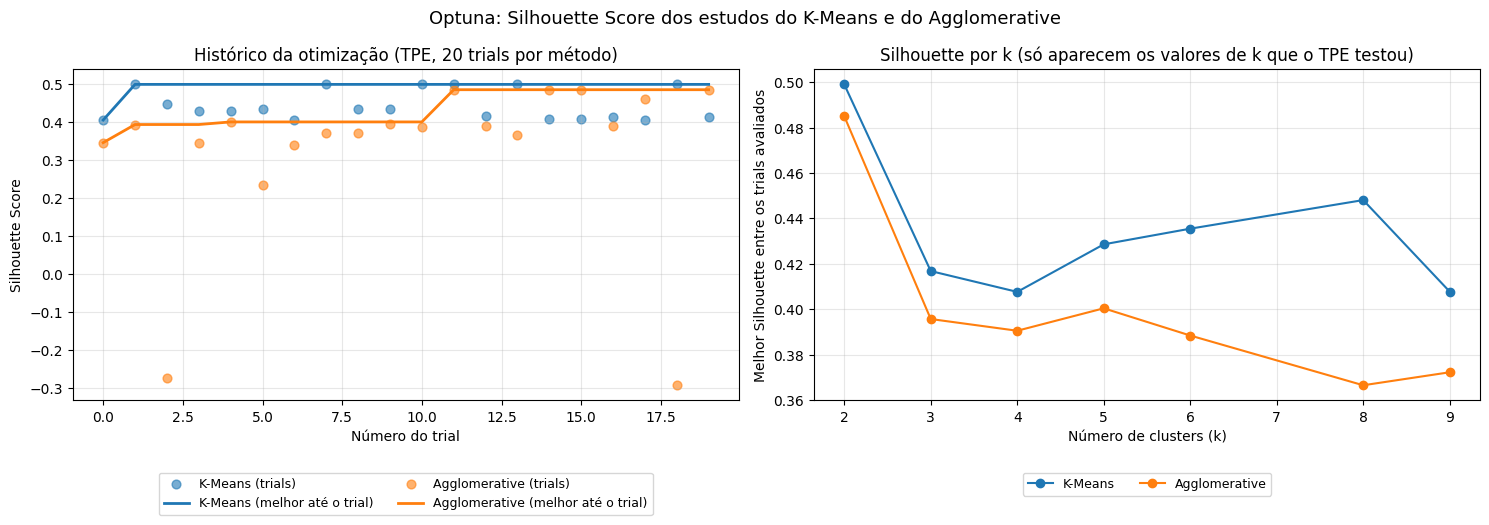

Gráfico salvo em: campinas_optuna_silhouette.png


In [ ]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))

# --- Painel 1: Silhouette de cada trial e melhor valor acumulado ---
ax = eixos[0]
for estudo, nome, cor in [(study_kmeans, 'K-Means', 'tab:blue'),
                          (study_agglomerative, 'Agglomerative', 'tab:orange')]:
    trials_ok = [t for t in estudo.trials if t.state == optuna.trial.TrialState.COMPLETE]
    valores = [t.value for t in trials_ok]
    ax.scatter(range(len(valores)), valores, color=cor, alpha=0.6, s=40,
               label=f'{nome} (trials)')
    ax.plot(range(len(valores)), np.maximum.accumulate(valores), color=cor, lw=2,
            label=f'{nome} (melhor até o trial)')
ax.set_xlabel('Número do trial')
ax.set_ylabel('Silhouette Score')
if N_TRIALS_KMEANS == N_TRIALS_AGG:
    _txt_trials = f'{N_TRIALS_KMEANS} trials por método'
else:
    _txt_trials = f'{N_TRIALS_KMEANS} trials no K-Means e {N_TRIALS_AGG} no Agglomerative'
ax.set_title(f'Histórico da otimização (TPE, {_txt_trials})')
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

# --- Painel 2: melhor Silhouette por k, entre os trials avaliados ---
ax = eixos[1]
for tab, nome, cor in [(tab_kmeans, 'K-Means', 'tab:blue'),
                       (tab_agg, 'Agglomerative', 'tab:orange')]:
    por_k = tab.groupby('k')['silhouette'].max().sort_index()
    ax.plot(por_k.index, por_k.values, marker='o', color=cor, label=nome)
ax.set_xticks(range(K_MIN_OPT, K_MAX_OPT + 1))
ax.set_xlabel('Número de clusters (k)')
ax.set_ylabel('Melhor Silhouette entre os trials avaliados')
ax.set_title('Silhouette por k (só aparecem os valores de k que o TPE testou)')
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

plt.suptitle('Optuna: Silhouette Score dos estudos do K-Means e do Agglomerative', fontsize=13)
plt.tight_layout()
plt.savefig('campinas_optuna_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfico salvo em: campinas_optuna_silhouette.png")

## 7.8. Seleção do método (configuração geral)

In [ ]:
"""
Comparação de study_kmeans.best_value com study_agglomerative.best_value. O método
com o maior Silhouette é a configuração geral da otimização. A diferença entre os dois é
mostrada para que o resultado não seja lido como mais forte do que é: diferenças
pequenas de Silhouette indicam métodos praticamente equivalentes nesta métrica.
"""

if trial_kmeans.value >= trial_agg.value:
    metodo_geral = 'kmeans'
    nome_geral = 'K-Means'
else:
    metodo_geral = 'agglomerative'
    nome_geral = 'Agglomerative'
diferenca_silhouette = abs(trial_kmeans.value - trial_agg.value)

print(f"Melhor Silhouette do K-Means      : {trial_kmeans.value:.4f}")
print(f"Melhor Silhouette do Agglomerative: {trial_agg.value:.4f}")
print(f"Diferença entre os métodos        : {diferenca_silhouette:.4f}")
print(f"\nConfiguração geral selecionada pela otimização: {nome_geral}")
if metodo_geral == 'kmeans':
    print("  ", descrever_hiperparametros('kmeans', hp_kmeans))
else:
    print("  ", descrever_hiperparametros('agglomerative', hp_agg))

Melhor Silhouette do K-Means      : 0.4991
Melhor Silhouette do Agglomerative: 0.4851
Diferença entre os métodos        : 0.0140

Configuração geral selecionada pela otimização: K-Means
   k=2, init=k-means++, n_init=5


## 7.9. Aplicação do OSRM aos cenários

In [ ]:
"""
Nesta etapa, o OSRM é consultado para avaliar quatro cenários: baseline K-Means,
baseline Agglomerative, melhor K-Means e melhor Agglomerative. Cada cenário usa
get_dist_paths_centers() (Seção 3.1) para obter as rotas e os cálculos de T3 e
Total_Time já definidos. As rotas consultadas ficam em CACHE_ROTAS e podem ser
reutilizadas.
"""


def construir_cenario(rotulo: str, metodo: str, hp: dict) -> dict:
    """
    Aplica a configuração, consulta as rotas no OSRM e calcula distâncias, T3 e
    Total_Time. Devolve um dicionário com tudo o que a tabela e o mapa precisam.
    """
    k = hp['n_clusters']
    coluna = f'{metodo}{k}'
    if metodo == 'kmeans':
        df_cl, centers = aplicar_kmeans_opt(
            df_ocorrencias_campinas, n_clusters=k, coluna_cluster=coluna,
            init=hp['init'], n_init=hp['n_init'], random_state=RANDOM_STATE)
    else:
        df_cl, centers = aplicar_agglomerative_opt(
            df_ocorrencias_campinas, n_clusters=k, coluna_cluster=coluna,
            linkage=hp['linkage'], metric=hp['metric'])

    silhouette = calcular_silhouette(df_cl, coluna)

    # Rotas OSRM (base -> cada ocorrência do seu cluster)
    vD_log, vD_route = get_dist_paths_centers(df_cl, coluna, centers)

    # Atribui as distâncias às ocorrências e calcula T3 e Total_Time
    df_cl['Distancia_km'] = np.nan
    for cluster_id_str, distancias in vD_log.items():
        idx = df_cl[df_cl[coluna] == int(cluster_id_str)].index
        df_cl.loc[idx, 'Distancia_km'] = distancias
    df_cl['T3'] = (df_cl['Distancia_km'] / VELOCIDADE_MEDIA_KMH) * 60
    df_cl['Total_Time'] = (df_cl['T1'] + df_cl['T2'] + df_cl['T3']
                           + df_cl['T4'] + df_cl['T5'])

    # Registra eventuais falhas apenas como aviso técnico de execução.
    total_falhas = int(df_cl['Distancia_km'].isna().sum())
    if total_falhas > 0:
        print(f"[Aviso] {rotulo}: {total_falhas} rota(s) não puderam ser calculadas "
              f"pelo OSRM e ficaram como NaN.")

    tamanhos = df_cl[coluna].value_counts()
    ic_inf, ic_sup = calculate_confidence_interval(df_cl['Total_Time'].values)
    return {
        'rotulo': rotulo, 'metodo': metodo, 'hp': hp, 'k': k, 'coluna': coluna,
        'df': df_cl, 'centers': centers, 'rotas': vD_route,
        'resumo': {
            'Cenário': rotulo,
            'Método': 'K-Means' if metodo == 'kmeans' else 'Agglomerative',
            'Hiperparâmetros': descrever_hiperparametros(metodo, hp),
            'k': k,
            'Silhouette': silhouette,
            'Dist. média (km)': df_cl['Distancia_km'].mean(),
            'Dist. máxima (km)': df_cl['Distancia_km'].max(),
            'T3 médio (min)': df_cl['T3'].mean(),
            'T3 máximo (min)': df_cl['T3'].max(),
            'Total_Time médio (min)': df_cl['Total_Time'].mean(),
            'IC 95% Total_Time (min)': f"({ic_inf:.2f}; {ic_sup:.2f})",
            'Maior cluster': int(tamanhos.max()),
            'Menor cluster': int(tamanhos.min()),
        },
    }


print("Calculando rotas via OSRM para os quatro cenários (pode levar alguns minutos)...")

hp_baseline_kmeans = {
    'n_clusters': BASELINE_K,
    'init': BASELINE_INIT,
    'n_init': BASELINE_N_INIT,
}
hp_baseline_agg = {
    'n_clusters': BASELINE_K,
    'linkage': BASELINE_LINKAGE_AGG,
    'metric': BASELINE_METRIC_AGG,
}

cenario_baseline_kmeans = construir_cenario(
    'Baseline: K-Means k=5', 'kmeans', hp_baseline_kmeans)
cenario_baseline_agg = construir_cenario(
    'Baseline: Agglomerative k=5 (Ward)', 'agglomerative', hp_baseline_agg)
cenario_kmeans = construir_cenario(
    'Melhor K-Means (Optuna)', 'kmeans', hp_kmeans)
cenario_agg = construir_cenario(
    'Melhor Agglomerative (Optuna)', 'agglomerative', hp_agg)

cenarios = [
    cenario_baseline_kmeans,
    cenario_baseline_agg,
    cenario_kmeans,
    cenario_agg,
]


Calculando rotas via OSRM para os quatro cenários (pode levar alguns minutos)...


## 7.10. Comparação final: baseline x melhores configurações do Optuna

In [ ]:
tabela_cenarios = pd.DataFrame([c['resumo'] for c in cenarios]).set_index('Cenário')
cenario_otimizado_geral = (
    cenario_kmeans if metodo_geral == 'kmeans' else cenario_agg
)
tabela_cenarios['Configuração geral'] = [
    'sim' if c is cenario_otimizado_geral else ''
    for c in cenarios
]

print("Comparação dos quatro cenários (Silhouette = qualidade interna; "
      "distância e T3 = deslocamento via OSRM):")
try:
    display(tabela_cenarios.round(2))
except NameError:
    print(tabela_cenarios.round(2))

print(f"\nConfiguração geral da otimização: {nome_geral}")
for c, baseline in [
    (cenario_kmeans, cenario_baseline_kmeans),
    (cenario_agg, cenario_baseline_agg),
]:
    r = c['resumo']
    base = baseline['resumo']
    dif_t3 = r['T3 médio (min)'] - base['T3 médio (min)']
    dif_pct = dif_t3 / base['T3 médio (min)'] * 100
    dif_sil = r['Silhouette'] - base['Silhouette']
    print(f"- {r['Cenário']} ({r['Hiperparâmetros']}), em relação ao "
          f"{base['Cenário']}: Silhouette {dif_sil:+.4f} | "
          f"k {r['k'] - base['k']:+d} | T3 médio {dif_t3:+.2f} min "
          f"({dif_pct:+.1f}%).")

Comparação dos quatro cenários (Silhouette = qualidade interna; distância e T3 = deslocamento via OSRM):


,Método,Hiperparâmetros,k,Silhouette,Dist. média (km),Dist. máxima (km),T3 médio (min),T3 máximo (min),Total_Time médio (min),IC 95% Total_Time (min),Maior cluster,Menor cluster,Configuração geral
Cenário,,,,,,,,,,,,,
Baseline: K-Means k=5,K-Means,"k=5, init=k-means++, n_init=10",5,0.43,9.58,26.49,14.37,39.74,42.64,(40.77; 44.51),43,22,
Baseline: Agglomerative k=5 (Ward),Agglomerative,"k=5, linkage=ward, metric=euclidean",5,0.40,10.35,32.66,15.52,48.99,43.80,(42.03; 45.56),54,20,
Melhor K-Means (Optuna),K-Means,"k=2, init=k-means++, n_init=5",2,0.50,13.59,30.64,20.38,45.97,48.65,(46.57; 50.74),76,74,sim
Melhor Agglomerative (Optuna),Agglomerative,"k=2, linkage=average, metric=manhattan",2,0.49,14.01,29.79,21.02,44.68,49.29,(47.29; 51.29),83,67,



Configuração geral da otimização: K-Means
- Melhor K-Means (Optuna) (k=2, init=k-means++, n_init=5), em relação ao Baseline: K-Means k=5: Silhouette +0.0705 | k -3 | T3 médio +6.02 min (+41.9%).
- Melhor Agglomerative (Optuna) (k=2, linkage=average, metric=manhattan), em relação ao Baseline: Agglomerative k=5 (Ward): Silhouette +0.0847 | k -3 | T3 médio +5.49 min (+35.4%).


## 7.11. Mapas dos cenários

In [ ]:
"""
Os mapas reaproveitam get_route_map() (Seção 3.2): ocorrências, áreas, bases e rotas.
Como os mapas dos cenários são parecidos, um título no canto identifica cada um.
"""

import folium


def adicionar_titulo_ao_mapa(mapa: folium.Map, texto: str) -> folium.Map:
    """Escreve um título fixo no canto do mapa, para identificar método e k."""
    html = ('<div style="position: fixed; top: 10px; left: 55px; z-index: 9999; '
            'background: white; padding: 6px 10px; border: 1px solid #888; '
            'border-radius: 4px; font-size: 14px;"><b>' + texto + '</b></div>')
    mapa.get_root().html.add_child(folium.Element(html))
    return mapa


def gerar_mapa_do_cenario(cenario: dict, sufixo: str) -> folium.Map:
    mapa = get_route_map(cenario['df'], cenario['coluna'], cenario['centers'],
                         cenario['rotas'])
    r = cenario['resumo']
    mapa = adicionar_titulo_ao_mapa(
        mapa, f"{r['Cenário']} | {r['Hiperparâmetros']} | T3 médio = {r['T3 médio (min)']:.1f} min")
    nome_arquivo = f"campinas_mapa_optuna_{sufixo}.html"
    mapa.save(nome_arquivo)
    print(f"Mapa salvo em: {nome_arquivo}")
    return mapa

### 7.11.1. Baseline: K-Means k=5

In [ ]:
mapa_baseline_kmeans = gerar_mapa_do_cenario(
    cenario_baseline_kmeans, 'baseline_kmeans5')
mapa_baseline_kmeans

Mapa salvo em: campinas_mapa_optuna_baseline_kmeans5.html


### 7.11.2. Baseline: Agglomerative Clustering (Ward)

In [ ]:
mapa_baseline_agg = gerar_mapa_do_cenario(
    cenario_baseline_agg,
    'baseline_agglomerative5_ward'
)
mapa_baseline_agg

Mapa salvo em: campinas_mapa_optuna_baseline_agglomerative5_ward.html


### 7.11.3. Melhor configuração do K-Means

In [ ]:
mapa_melhor_kmeans = gerar_mapa_do_cenario(cenario_kmeans, f"melhor_kmeans{cenario_kmeans['k']}")
mapa_melhor_kmeans

Mapa salvo em: campinas_mapa_optuna_melhor_kmeans2.html


### 7.11.4. Melhor configuração do Agglomerative

In [ ]:
mapa_melhor_agg = gerar_mapa_do_cenario(cenario_agg, f"melhor_agglomerative{cenario_agg['k']}")
mapa_melhor_agg

Mapa salvo em: campinas_mapa_optuna_melhor_agglomerative2.html


### 7.12. Conclusão da Otimização: O Trade-off entre Geometria e Operação

A execução da otimização de hiperparâmetros via Optuna revelou um aspecto fundamental do problema de alocação de bases de ambulâncias: a configuração matematicamente "ideal" para agrupamento espacial não é necessariamente a melhor configuração para a operação logística.
1. Geometria vs. Tempo de Resposta: No K-Means, a configuração otimizada com \(k=2\) apresentou aumento de aproximadamente 41,9% no tempo médio de deslocamento em relação ao baseline com \(k=5\). No Agglomerative Clustering, a configuração otimizada também selecionou \(k=2\), resultando em aumento de aproximadamente 35,4% em relação ao respectivo baseline.
2. Limitação de Métricas Tradicionais: O Silhouette Score foi calculado com distância euclidiana sobre as coordenadas geográficas, sem considerar diretamente a estrutura da rede viária.
3. Direções Futuras (Fronteira de Pareto): Uma evolução metodológica valiosa seria formular o Optuna como um problema multiobjetivo, instruindo o algoritmo a buscar um compromisso ótimo (trade-off) entre maximizar a qualidade dos clusters (Silhouette) e minimizar a distância métrica aproximada ou o tempo de deslocamento, revelando a Fronteira de Pareto das alocações possíveis.